<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_ExperimentalAttacks_Maussner2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimental attacks on quantum computing and quantum machine learning: Maußner and Reers (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Marc Maußner and Volker Reers, "Experimental Attacks on Quantum Computing and Quantum Machine Learning",
> *Proceedings of the 24th European Conference on Cyber Warfare and Security (ECCWS 2025)*, pp. 864-873.
> DOI 10.34190/eccws.24.1.3463 (infoteam Software AG and Qseidon GmbH).
> (The repository manifest lists the first author as "Muner", which is a file-name transcription of Maußner.)

The authors published the code of every experiment (public domain, Unlicense): <https://github.com/MarcMaussner/qml_cysec>. This notebook
re-implements those experiments from the paper text and the authors' notebooks (pinned commit
`246accafc6d25caec9c8133d1c2cb5ccabf32727`, folders `crosstalk/`, `transpilation/`, `qml/one_pixel/`, `qml/adversarial_pennylane/`), runs them on
simulators and adds what the paper leaves open: control runs without the attack, the statistics of the gate-count threshold, a classical
baseline, success rates over the whole test set instead of one image, and a verdict per claim.

**What the paper does.** It is a proof-of-concept paper with four small experiments on the confidentiality-integrity-availability (CIA) triad
of quantum computing and QML:

1. **Crosstalk / fault injection** (Sec. 3.1, 4.1): a harmless-looking circuit (an even number of Hadamard or CNOT gates next to a GHZ
   circuit) corrupts the GHZ output on a noisy "fake" device and on IBM hardware, and the number of gates needed for visible damage is estimated.
2. **Transpiler tampering** (Sec. 3.2, 4.2): a custom Qiskit transpiler pass silently doubles every `X` gate, i.e. cancels it.
3. **One-pixel attack** (Sec. 3.3, 4.3): one pixel of an 8x8 digit image is changed until a 6-qubit amplitude-encoded classifier errs.
4. **PGD and FGSM gradient attacks** (Sec. 3.3, 4.3) on an 8-qubit, 32-layer `StronglyEntanglingLayers` classifier of the *plus-minus* images.

**How to run.** Colab, CPU runtime, Runtime -> Run all. `FAST_MODE = True` (default in the configuration cell) finishes in about 10 minutes on a
laptop CPU; `FAST_MODE = False` uses the authors' budgets and takes roughly 1 hour. No Hugging Face token is needed: every dataset used here is
public and ungated (scikit-learn `load_digits` and the plus-minus file from the authors' repository). Real IBM hardware is used only if you put a
token in `IBM_TOKEN`.

**What you get at the end.** Histograms that reproduce the paper's Figures 9 and 12, the gate-count thresholds of Section 4.1, the tampered
circuit of Figure 11, the one-pixel and PGD/FGSM results of Figures 13 and 14, a classical baseline, and a table that puts every number of the paper
next to the number computed here with a verdict ("reproduced", "not reached", "exceeded", "cannot be checked").

## The paper in one page

**Problem.** Quantum computers and QML models will be attacked like any other IT asset. The authors build the smallest possible experiments that
break one CIA-triad asset each: the *integrity* of a circuit's output (crosstalk, transpiler tampering) and of a QML model's prediction (adversarial
inputs).

**Experiment 1, crosstalk (Sec. 3.1).** Target circuit: a GHZ state on q0..q3 of a 5-qubit device (`H(0), CX(0,1), CX(1,2), CX(2,3)`, q4 idle). Ideal
output `00000` / `01111` with 50 % each (Qiskit bit order, q4 on the left). Attack A: 10 000 `H` gates on the idle qubit q4. Attack B: 1 000 `CX` gates
on q3,q4. Both are even in number, so ideally they change nothing. On a noisy device each gate adds a little error, and the errors of a gate leak to
its coupled neighbours ("crosstalk"). The authors run 1 000 shots on a fake device with the coupling map of Saki et al. (2020), then on `ibm_sherbrooke`
(Fig. 9, 10), and loop over the number of attack gates until more than two outcomes exceed 10 % of the shots (fake `ibm_sherbrooke`).

**Experiment 2, transpiler tampering (Sec. 3.2).** Target: GHZ on q0,q1,q2 with an extra `X` on q1 (ideal outputs `00010` and `00101`). A custom
`TransformationPass` replaces every `x` node of the transpiled DAG by two `x` nodes (net identity). Running the tampered circuit gives `00000` and
`00111`. Countermeasure (Sec. 5): an equivalence check by inverse execution.

**Experiment 3, one pixel (Sec. 3.3).** Digits 0 and 1 of scikit-learn's 8x8 digits, amplitude encoding into 6 qubits plus a trainable ansatz, 80/20
split. One random test image is attacked by changing one random pixel at a time until the prediction flips. "We just inspected if the attack was
successful"; quantification is left to future work.

**Experiment 4, PGD and FGSM (Sec. 3.3).** PennyLane *plus-minus* images (4 classes), 8 qubits, 32 `StronglyEntanglingLayers`, 4 qubits measured, PyTorch
layer, cross-entropy, Adam with learning rate 0.1. PGD and FGSM perturb 4 representative images (one per class); the paper reports **3 of 4
misclassified** for both.

**Claims.** (C1) H-gate attack adds `10000` and `11111` to the histogram; (C2) CX attack adds six more states with almost equal probability;
(C3) the same on real hardware (`ibm_sherbrooke`); (C4) about 2 300-2 400 `H` gates are needed; (C5) about 140-160 `CX` gates are needed;
(C6) the tampering pass yields `00000`/`00111`; (C7) the one-pixel attack succeeds; (C8) PGD fools 3 of 4 images; (C9) FGSM fools 3 of 4 images.

## What follows the paper and what had to be chosen

The paper omits most hyper-parameters; the authors' repository (pinned commit) fixes them, and this notebook follows the repository wherever the
paper is silent. Items that the repository leaves open too are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Crosstalk device (Fig. 2) | "fake device" with the coupling map of Saki et al. (figure not readable as text) | the authors' `GenericBackendV2`: 5 qubits, basis `id, rz, sx, x, cx`, coupling triangle (0,1,2) plus 2-3, 2-4, 3-4, `x` error 1e-4, `cx` error 2e-2, other calibration values from `GenericBackendV2(seed=42)` |
| Order of attack and target gates | "add a new circuit to the target circuit" | attack gates first, then the GHZ circuit, as in the authors' code; transpiler optimisation level 0 so that nothing is cancelled |
| Simulator | Qiskit sampler on the fake device, 1 000 shots | `AerSimulator.from_backend(device)` (the noise model built from the device), 1 000 shots, seeds fixed |
| Real hardware (Fig. 10) | `ibm_sherbrooke` | runs only if `IBM_TOKEN` is set; otherwise "cannot be checked" |
| Gate-count loop (Sec. 4.1) | loop until more than 2 outcomes have more than 10 % of the shots, on a fake `ibm_sherbrooke` | same stopping rule on `FakeSherbrooke` (qubits 0-4 form a line there); the loop is repeated 200 times from one precise distribution to give mean and spread; the authors' step is 100 `H` / 20 `CX` gates |
| Transpiler attack | pass inserts an extra `X` after every `X`, then PassManager, draw, run | the authors' `AddXGateOptimizer`, applied to the transpiled circuit, plus the inverse-execution countermeasure and an operator-equivalence check |
| One-pixel data | "MNIST from scikit-learn" (8x8, values said to be 0-255) | `load_digits` classes 0 and 1; the pixel scale is 0-16, not 0-255; the authors drop the last image of each class (358 images) and divide by the pixel sum |
| One-pixel model | 6 qubits, amplitude encoding, trainable ansatz (Fig. 7 not readable) | the authors' ansatz: per qubit `RX, RY, RX` and a ring of `CNOT`s, output = sum of `<Z_i>` + bias, square loss, gradient descent 0.3, 200 steps, 80/20 split (`random_state=42`) |
| One-pixel rule | lighter pixel -> black, darker pixel -> white | two rules are run: the **repository rule** (pixel in sum-normalised units: `> 0.5 -> 0.5`, else `-> 1.0`, which sets the pixel to a value 20-100x larger than the others) and the **paper-text rule** (raw 0-16 scale: `< 8 -> 16`, else `-> 0`) |
| One-pixel statistics | one random image, success yes/no | the same, plus the success rate over all test images and the same attack against three classical models (logistic regression, RBF-SVM, random forest) |
| PGD/FGSM model | 8 qubits, 32 `StronglyEntanglingLayers`, 4 qubits measured, PyTorch, CE loss, Adam 0.1 | the authors' model: 256 pixels repeated 3x as rotation scale, `angles = w * x + b` (1 536 parameters), 4 epochs, batch 20, init `0.1 * rand`, the PennyLane `default.qubit` simulator with PyTorch back-propagation and batched input |
| PGD/FGSM data | text: train 1 000, test 200 | the authors' code: first 200 training and first 50 test images of the 1 000/200 file (the text and the code disagree; the code is followed) |
| Attack strength | not stated | repository: epsilon 0.1 (L-infinity), PGD step 0.01, 10 iterations, no random start, no clipping to [0, 1] |
| Representatives | "4 chosen representatives of each class" | first image of each class in the training file, as in the repository |
| Classical baseline | none | one-pixel: LR, SVC(rbf), RandomForest; PGD/FGSM: a 256-32-4 MLP trained on the same images and attacked with the same epsilon |
| Seeds | not fixed | `SEED = 42` everywhere; the quantum PGD model is trained once (cost), the one-pixel experiment over several seeds |

In [1]:
# Installs pinned to the tested versions; skipped locally when everything is already importable.
import importlib.util, sys
IN_COLAB = "google.colab" in sys.modules
_missing = [m for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime", "h5py", "torch", "pylatexenc")
            if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc h5py
    print("Installed. If Colab asks for a session restart, restart and run all again.")
else:
    print("All libraries already available; nothing to install.")

All libraries already available; nothing to install.


In [2]:
# ---------------------------------------------------------------- CONFIGURATION (every tunable constant) ----
import os, time
SEED = 42
FAST_MODE = False     # True: about 10 minutes (class demo). False: the authors' budgets, about 1 hour on a laptop CPU.
IBM_TOKEN = ""              # optional: IBM Quantum token for the real-hardware cell of section 3 (left empty = skipped)
DATA_DIR = "qc159_data"     # downloads are cached here
os.makedirs(DATA_DIR, exist_ok=True)

SHOTS = 1000                # shots of every histogram in the paper
CODE_COMMIT = "246accafc6d25caec9c8133d1c2cb5ccabf32727"   # github.com/MarcMaussner/qml_cysec, the commit this notebook was built from

# ---- Experiment 1: crosstalk -------------------------------------------------------------------
N_H_ATTACK, N_CX_ATTACK = 10_000, 1_000        # Fig. 9: number of attack gates
HI_SHOTS = 20_000                              # one precise run per sweep point; 1000-shot loops are then emulated from it
N_VIRTUAL_LOOPS = 200                          # emulated 1000-shot loops per sweep (the paper ran each loop once)
if FAST_MODE:
    H_GRID  = list(range(0, 5001, 200))        # the authors step by 100
    CX_GRID = list(range(0, 401, 20))          # the authors step by 20
    N_EXTRA_LAYOUTS = 0                        # other 5-qubit lines of Sherbrooke as a sensitivity check
else:
    H_GRID  = list(range(0, 6001, 100))
    CX_GRID = list(range(0, 401, 10))
    N_EXTRA_LAYOUTS = 2
EXTRA_H_GRID, EXTRA_CX_GRID = list(range(0, 6001, 400)), list(range(0, 401, 20))

# ---- Experiment 3: one pixel ------------------------------------------------------------------
OP_STEPS, OP_LR = 200, 0.3                     # the authors' gradient descent
OP_SEEDS = [SEED, SEED + 1] if FAST_MODE else [SEED + i for i in range(5)]

# ---- Experiment 4: PGD / FGSM ----------------------------------------------------------------
PM_QUBITS, PM_LAYERS, PM_REUP, PM_CLASSES = 8, 32, 3, 4
PM_LR, PM_BATCH = 0.1, 20
if FAST_MODE:
    PM_N_TRAIN, PM_N_TEST, PM_EPOCHS = 200, 20, 2    # authors: 200 / 50 / 4 (fewer test images and epochs here)
else:
    PM_N_TRAIN, PM_N_TEST, PM_EPOCHS = 200, 50, 4    # the authors' subset and epochs
EPS, ALPHA, PGD_ITERS = 0.1, 0.01, 10                # epsilon, PGD step, PGD iterations (authors)
EPS_SWEEP = [0.05, 0.1] if FAST_MODE else [0.025, 0.05, 0.1, 0.2]
MLP_EPOCHS = 60                                      # CHOICE: classical baseline, enough to reach its plateau
print("FAST_MODE =", FAST_MODE)

FAST_MODE = False


In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import torch, torch.nn.functional as F
import pennylane as qml, qiskit, qiskit_aer, qiskit_ibm_runtime, h5py, sklearn
from qiskit import QuantumCircuit
from qiskit.converters import circuit_to_dag
from qiskit.dagcircuit import DAGCircuit
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator
from qiskit.transpiler import InstructionProperties, PassManager, TransformationPass
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

torch.set_default_dtype(torch.float64)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.25})
print({"python": sys.version.split()[0], "numpy": np.__version__, "torch": torch.__version__, "pennylane": qml.__version__,
       "qiskit": qiskit.__version__, "qiskit-aer": qiskit_aer.__version__, "qiskit-ibm-runtime": qiskit_ibm_runtime.__version__,
       "scikit-learn": sklearn.__version__})
T0 = time.time(); RES = {}          # RES collects every number that the final comparison needs

{'python': '3.12.10', 'numpy': '2.5.4', 'torch': '2.14.1+cpu', 'pennylane': '0.45.1', 'qiskit': '2.5.2', 'qiskit-aer': '0.17.2', 'qiskit-ibm-runtime': '0.50.0', 'scikit-learn': '1.9.1'}


## 1. Data

Two real datasets are used, both public and ungated (no Hugging Face token needed):

* **scikit-learn digits** (`load_digits`, shipped with scikit-learn): 1 797 handwritten digits as 8x8 images with pixel values 0-16. The paper calls it
  "MNIST from scikit-learn" and says the values are 0-255; the real scale is 0-16. Only the digits 0 and 1 are used. As in the authors' code, the last
  image of each class is dropped (177 zeros and 181 ones remain) and each image is divided by its pixel sum before amplitude encoding.
* **plus-minus** images of PennyLane's dataset library (1 000 training and 200 test images of 16x16 pixels, four symbol classes). The file is downloaded from
  the authors' repository (pinned commit), where it sits next to their PGD/FGSM notebooks; if GitHub is unreachable the notebook falls back to
  `qml.data.load("other", name="plus-minus")`.

The crosstalk and transpiler experiments (sections 3 and 4) have no dataset: their input is a quantum circuit and their output is a histogram of measured
bit strings.

In [4]:
import urllib.request, glob

# ---- scikit-learn digits, classes 0 and 1 (authors' code: drop the last image of each class) ----
_d = load_digits()
_i0 = np.where(_d.target == 0)[0][:-1]; _i1 = np.where(_d.target == 1)[0][:-1]      # CHOICE: authors' [0:-1]
_idx = np.concatenate([_i0, _i1])
D_RAW = _d.data[_idx].astype(np.float64)               # (n, 64), pixel values 0..16
D_Y = _d.target[_idx].astype(int)
D_IMG = _d.images[_idx]
D_SUMNORM = D_RAW / D_RAW.sum(axis=1, keepdims=True)   # authors' preprocessing: divide by the pixel sum
print("digits 0/1:", D_RAW.shape, "class counts", dict(zip(*np.unique(D_Y, return_counts=True))), "pixel range", D_RAW.min(), D_RAW.max())

# ---- plus-minus ----
PM_URL = (f"https://raw.githubusercontent.com/MarcMaussner/qml_cysec/{CODE_COMMIT}/qml/adversarial_pennylane/pgd/datasets/other/"
          "PlusMinus/PlusMinus_PlusMinus.h5")
PM_PATH = os.path.join(DATA_DIR, "plus-minus.h5")
if not os.path.exists(PM_PATH):
    try:
        urllib.request.urlretrieve(PM_URL, PM_PATH)
        print("downloaded", PM_PATH, os.path.getsize(PM_PATH), "bytes from the authors' repository")
    except Exception as e:
        print("GitHub download failed (%s); falling back to qml.data.load" % type(e).__name__)
        qml.data.load("other", name="plus-minus", directory=DATA_DIR)
        PM_PATH = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.h5"), recursive=True))[0]
with h5py.File(PM_PATH, "r") as f:
    PM_KEYS = list(f.keys())
    PM_XTR, PM_YTR = f["img_train"][:].astype(np.float64), f["labels_train"][:].astype(int)
    PM_XTE, PM_YTE = f["img_test"][:].astype(np.float64), f["labels_test"][:].astype(int)
print("plus-minus file keys:", PM_KEYS, "| train", PM_XTR.shape, "test", PM_XTE.shape, "| pixel range", PM_XTR.min(), PM_XTR.max())

digits 0/1: (358, 64) class counts {np.int64(0): np.int64(177), np.int64(1): np.int64(181)} pixel range 0.0 16.0


downloaded qc159_data\plus-minus.h5 1247040 bytes from the authors' repository
plus-minus file keys: ['img_test', 'img_train', 'labels_test', 'labels_train'] | train (1000, 16, 16) test (200, 16, 16) | pixel range 0.0 1.0


## Dataset Exploration and Visualisation

This section shows the data the models really use: shape, feature names, the original label values and class counts, the real class distribution,
sample images, and two-dimensional scatter plots in which **every point is a real image coloured by its ground-truth class**. Both models encode the
image as amplitudes (not as angles), so there is no [0, pi] angle scaling; the second scatter of each dataset shows the L2-normalised pixel vector, which is
exactly the state the circuit receives. All PCA transforms are fitted on the training split only; test images are projected with the same transform.

shape: (358, 64) | train (286, 64) | test (72, 64)
feature names: ['pixel_r0_c0', 'pixel_r0_c1', 'pixel_r0_c2', 'pixel_r0_c3'] ... pixel_r7_c7  (64 pixels)
original label values: [0, 1] -> {0: 'digit 0', 1: 'digit 1'}


,all,train,test
digit 0,177,139,38
digit 1,181,147,34


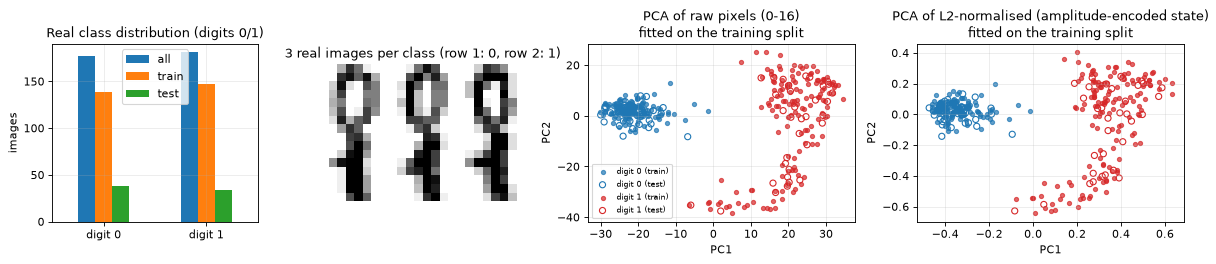

In [5]:
# ---------------- digits 0/1 ----------------
DX_TR, DX_TE, DY_TR, DY_TE, DR_TR, DR_TE = train_test_split(D_SUMNORM, D_Y, D_RAW, train_size=0.8, random_state=SEED)  # authors: train_size 0.8, rs 42
D_NAMES = {0: "digit 0", 1: "digit 1"}
print("shape:", D_RAW.shape, "| train", DX_TR.shape, "| test", DX_TE.shape)
print("feature names:", [f"pixel_r{r}_c{c}" for r in range(8) for c in range(8)][:4], "...", "pixel_r7_c7  (64 pixels)")
print("original label values:", sorted(np.unique(D_Y).tolist()), "->", D_NAMES)
cnt = pd.DataFrame({"all": np.bincount(D_Y), "train": np.bincount(DY_TR), "test": np.bincount(DY_TE)}, index=list(D_NAMES.values()))
display(cnt)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1, 1, 1.3, 1.3]})
cnt.plot.bar(ax=ax[0], rot=0); ax[0].set_title("Real class distribution (digits 0/1)"); ax[0].set_ylabel("images")

ex = np.concatenate([np.hstack([D_IMG[D_Y == c][j] for j in range(3)]) for c in (0, 1)], axis=0)
ax[1].imshow(ex, cmap="gray_r"); ax[1].set_title("3 real images per class (row 1: 0, row 2: 1)"); ax[1].axis("off")
pca_raw = PCA(n_components=2, random_state=SEED).fit(DR_TR)
pca_l2 = PCA(n_components=2, random_state=SEED).fit(DR_TR / np.linalg.norm(DR_TR, axis=1, keepdims=True))
for a, (pca, tr, te, ttl) in zip(ax[2:], [(pca_raw, DR_TR, DR_TE, "raw pixels (0-16)"),
                                           (pca_l2, DR_TR / np.linalg.norm(DR_TR, axis=1, keepdims=True),
                                            DR_TE / np.linalg.norm(DR_TE, axis=1, keepdims=True), "L2-normalised (amplitude-encoded state)")]):
    Ztr, Zte = pca.transform(tr), pca.transform(te)
    for c, col in zip([0, 1], ["tab:blue", "tab:red"]):
        a.scatter(*Ztr[DY_TR == c].T, c=col, s=14, alpha=.7, label=f"{D_NAMES[c]} (train)")
        a.scatter(*Zte[DY_TE == c].T, facecolors="none", edgecolors=col, s=30, label=f"{D_NAMES[c]} (test)")
    a.set_title("PCA of " + ttl + "\nfitted on the training split"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

full file: train (1000, 16, 16) test (200, 16, 16) | model subset: train (200, 256) test (50, 256)
feature names: ['pixel_r0_c0', 'pixel_r0_c1', 'pixel_r0_c2'] ... pixel_r15_c15  (256 pixels)
original label values: [0, 1, 2, 3] -> {0: 'minus (-)', 1: 'plus (+)', 2: 'left tee (|-)', 3: 'right tee (-|)'}


,full train,used train,full test,used test
minus (-),250,50,50,8
plus (+),250,45,50,14
left tee (|-),250,47,50,14
right tee (-|),250,58,50,14


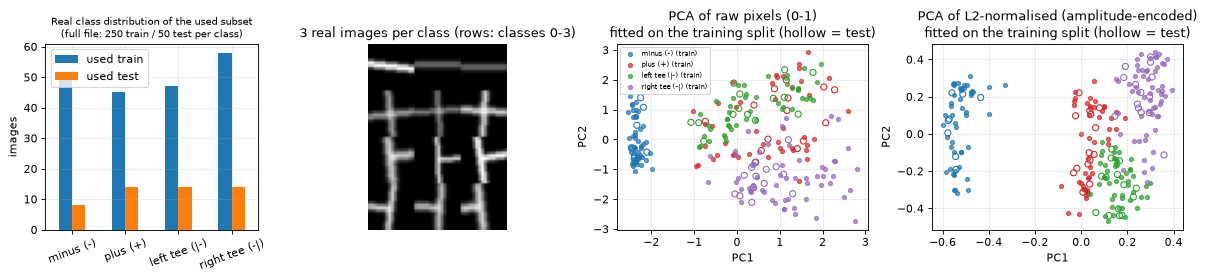

In [6]:
# ---------------- plus-minus ----------------
PM_NAMES = {0: "minus (-)", 1: "plus (+)", 2: "left tee (|-)", 3: "right tee (-|)"}   # names follow the authors' label glyphs
PM_COL = ["tab:blue", "tab:red", "tab:green", "tab:purple"]
PX_TR = PM_XTR[:PM_N_TRAIN].reshape(PM_N_TRAIN, -1); PY_TR = PM_YTR[:PM_N_TRAIN]       # the subset the PGD/FGSM model is trained on
PX_TE = PM_XTE[:PM_N_TEST].reshape(PM_N_TEST, -1);  PY_TE = PM_YTE[:PM_N_TEST]
print("full file: train", PM_XTR.shape, "test", PM_XTE.shape, "| model subset: train", PX_TR.shape, "test", PX_TE.shape)
print("feature names:", [f"pixel_r{r}_c{c}" for r in range(16) for c in range(16)][:3], "...", "pixel_r15_c15  (256 pixels)")
print("original label values:", sorted(np.unique(PM_YTR).tolist()), "->", PM_NAMES)
cnt = pd.DataFrame({"full train": np.bincount(PM_YTR, minlength=4), "used train": np.bincount(PY_TR, minlength=4),
                    "full test": np.bincount(PM_YTE, minlength=4), "used test": np.bincount(PY_TE, minlength=4)}, index=list(PM_NAMES.values()))
display(cnt)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.1, 1.2, 1.3, 1.3]})
cnt[["used train", "used test"]].plot.bar(ax=ax[0], rot=20); ax[0].set_title("Real class distribution of the used subset\n(full file: 250 train / 50 test per class)", fontsize=9); ax[0].set_ylabel("images")
grid = np.concatenate([np.hstack([PM_XTR[PM_YTR == c][j] for j in range(3)]) for c in range(4)], axis=0)
ax[1].imshow(grid, cmap="gray"); ax[1].set_title("3 real images per class (rows: classes 0-3)"); ax[1].axis("off")
l2 = lambda X: X / np.linalg.norm(X, axis=1, keepdims=True)
for a, (tr, te, ttl) in zip(ax[2:], [(PX_TR, PX_TE, "raw pixels (0-1)"), (l2(PX_TR), l2(PX_TE), "L2-normalised (amplitude-encoded)")]):
    pca = PCA(n_components=2, random_state=SEED).fit(tr)
    Ztr, Zte = pca.transform(tr), pca.transform(te)
    for c in range(4):
        a.scatter(*Ztr[PY_TR == c].T, c=PM_COL[c], s=14, alpha=.7, label=f"{PM_NAMES[c]} (train)")
        a.scatter(*Zte[PY_TE == c].T, facecolors="none", edgecolors=PM_COL[c], s=30)
    a.set_title("PCA of " + ttl + "\nfitted on the training split (hollow = test)"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
ax[2].legend(fontsize=6)
plt.tight_layout(); plt.show()

## 2. Building blocks

This section defines, without running any experiment yet, every circuit and device that the experiments execute, so that the next section can draw them.

* **Crosstalk circuits.** `attack_circuit(kind, n)` builds `n` attack gates (`H` on q4 or `CX` on q3,q4) in front of the 4-qubit GHZ circuit, followed by the
  measurement of all 5 qubits. The same function builds the 10 000-gate circuit that is executed and the short copies that are drawn.
* **Devices.** The authors' noisy 5-qubit "fake device" (Saki coupling map) and `FakeSherbrooke`, a snapshot of the 127-qubit `ibm_sherbrooke` noise
  model shipped with `qiskit-ibm-runtime`. In Sherbrooke, qubits 0-1-2-3-4 are a line.
* **Transpiler attack.** `AddXGateOptimizer`, a `TransformationPass` that replaces each `x` node of the DAG by two `x` nodes.
* **QML models.** The 6-qubit one-pixel classifier and the 8-qubit, 32-layer PGD/FGSM classifier as PennyLane QNodes with the PyTorch interface.

In [7]:
# ---------------------------------------------------------------- crosstalk circuits and devices ----------------------
def ghz_ops(qc):
    qc.h(0); qc.cx(0, 1); qc.cx(1, 2); qc.cx(2, 3)          # GHZ state of q0..q3, q4 stays |0>
    return qc

def attack_circuit(kind, n_gates, measure=True):
    """n_gates attack gates (kind 'h': H on q4; kind 'cx': CX on q3,q4) followed by the GHZ target, as in the authors' code."""
    qc = QuantumCircuit(5, 5)
    for _ in range(n_gates):
        qc.h(4) if kind == "h" else qc.cx(3, 4)
    ghz_ops(qc)
    if measure:
        qc.measure(range(5), range(5))
    return qc

SAKI_COUPLING = [[0, 1], [1, 0], [1, 2], [2, 1], [0, 2], [2, 0], [2, 3], [3, 2], [2, 4], [4, 2], [3, 4], [4, 3]]   # authors' code

def make_fake_device(seed=SEED):
    dev = GenericBackendV2(num_qubits=5, basis_gates=["id", "rz", "sx", "x", "cx"], coupling_map=SAKI_COUPLING, seed=seed)
    for q in range(5):                                                       # authors' error_rates = {"x_error": 1e-4, "cx_error": 2e-2}
        dev.target.update_instruction_properties("x", (q,), InstructionProperties(error=1e-4, duration=1e-8))
    for edge in dev.coupling_map:
        dev.target.update_instruction_properties("cx", tuple(edge), InstructionProperties(error=2e-2, duration=1e-8))
    return dev

FAKE = make_fake_device()
SIM_FAKE = AerSimulator.from_backend(FAKE)
PM_FAKE = generate_preset_pass_manager(optimization_level=0, backend=FAKE, seed_transpiler=SEED)

SHERB = FakeSherbrooke()
SIM_SHERB = AerSimulator.from_backend(SHERB)
def pm_sherb(layout=(0, 1, 2, 3, 4)):
    return generate_preset_pass_manager(optimization_level=0, backend=SHERB, initial_layout=list(layout), seed_transpiler=SEED)

def vec(counts, n=5):
    v = np.zeros(2 ** n)
    for k, c in counts.items():
        v[int(k.replace(" ", ""), 2)] += c
    return v / v.sum()

def run_counts(circ, pm, sim, shots=SHOTS, seed=SEED):
    return sim.run(pm.run(circ), shots=shots, seed_simulator=seed).result().get_counts()

IDEAL = {"00000", "01111"}
print("fake device:", FAKE.name, "| qubits", FAKE.num_qubits, "| basis", FAKE.operation_names, "| coupling", FAKE.coupling_map)
print("Sherbrooke  :", SHERB.name, "| qubits", SHERB.num_qubits, "| basis", SHERB.operation_names)

fake device: generic_backend_5q | qubits 5 | basis ['id', 'rz', 'sx', 'x', 'cx', 'reset', 'delay', 'measure'] | coupling [[0, 1], [1, 0], [1, 2], [2, 1], [0, 2], [2, 0], [2, 3], [3, 2], [2, 4], [4, 2], [3, 4], [4, 3]]
Sherbrooke  : fake_sherbrooke | qubits 127 | basis ['id', 'rz', 'if_else', 'reset', 'x', 'delay', 'ecr', 'switch_case', 'for_loop', 'sx', 'measure']


In [8]:
# ---------------------------------------------------------------- transpiler attack ----------------------
class AddXGateOptimizer(TransformationPass):
    """The authors' malicious pass: every x node of the DAG is replaced by two x nodes (net identity = the X gate disappears)."""
    def replacement_circ(self):
        qc = QuantumCircuit(1); qc.x(0); qc.x(0)
        return qc
    def run(self, dag: DAGCircuit) -> DAGCircuit:
        for node in dag.op_nodes():
            if node.op.name == "x":
                dag.substitute_node_with_dag(node, circuit_to_dag(self.replacement_circ()))
        return dag

def modified_ghz(measure=True):
    """Target of Sec. 3.2 (authors' code): GHZ-type circuit on q0..q2 with an X gate on q1. Ideal output 00010 / 00101."""
    qc = QuantumCircuit(5, 5)
    qc.h(0); qc.cx(0, 1); qc.x(1); qc.cx(0, 2)
    if measure:
        qc.measure(range(5), range(5))
    return qc

# ---------------------------------------------------------------- one-pixel QNode (6 qubits) ----------------------
OP_QUBITS = 6
dev_op = qml.device("default.qubit", wires=OP_QUBITS)
@qml.qnode(dev_op, interface="torch", diff_method="backprop")
def op_circuit(weights, x):
    qml.AmplitudeEmbedding(features=x, wires=range(OP_QUBITS), normalize=True)          # 64 amplitudes on 6 qubits
    for i in range(OP_QUBITS):                                                          # trainable ansatz of the authors
        qml.RX(weights[i, 0], wires=i); qml.RY(weights[i, 1], wires=i); qml.RX(weights[i, 2], wires=i)
        qml.CNOT(wires=[i, (i + 1) % OP_QUBITS])
    return qml.expval(qml.sum(*[qml.PauliZ(i) for i in range(OP_QUBITS)]))

# ---------------------------------------------------------------- PGD/FGSM QNode (8 qubits, 32 layers) ----------------------
dev_pm = qml.device("default.qubit", wires=PM_QUBITS)
@qml.qnode(dev_pm, interface="torch", diff_method="backprop")
def pm_circuit(angles):
    qml.StronglyEntanglingLayers(weights=angles, wires=range(PM_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(PM_CLASSES)]                       # only 4 of the 8 qubits are measured

PM_SHAPE = qml.StronglyEntanglingLayers.shape(n_layers=PM_LAYERS, n_wires=PM_QUBITS)    # (32, 8, 3)

class QMLClassifier(torch.nn.Module):
    """The authors' classifier: angles = weights * (pixels repeated 3x, reshaped to (32, 8, 3)) + bias, StronglyEntanglingLayers, <Z_0..3>."""
    def __init__(self, seed):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.weights = torch.nn.Parameter(0.1 * torch.rand(PM_SHAPE, generator=g))        # authors: 0.1 * rand
        self.bias = torch.nn.Parameter(0.1 * torch.rand(PM_SHAPE, generator=g))
    def forward(self, x):
        inp = torch.hstack([x] * PM_REUP).reshape(-1, *PM_SHAPE)
        return torch.stack(pm_circuit(self.weights * inp + self.bias), dim=-1).reshape(-1, PM_CLASSES)

print("QMLClassifier parameters:", sum(p.numel() for p in QMLClassifier(SEED).parameters()))

QMLClassifier parameters: 1536


## Quantum Circuit Architecture

Every drawing below is the object that is executed, produced by the same builder function or QNode as the experiments. Where the executed circuit is too
long to print (10 000 gates), the drawing uses the same builder with a handful of gates and a cell asserts that the executed circuit has exactly the
same gate list apart from the repetition count. The paper omits the ansatz of the one-pixel model (Fig. 7) and the circuit details of the PGD model; both
are taken from the authors' code and the omission is documented in the table above.

GHZ target (Fig. 3)                          qubits=5    depth=4       gates=4       trainable parameters=0

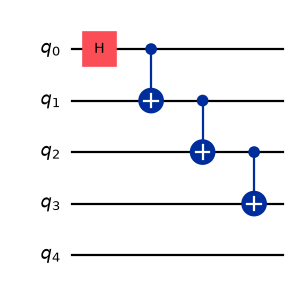

attack 'h' as executed (10000 gates)         qubits=5    depth=10001   gates=10009   trainable parameters=0
   drawing below: same builder, 4 attack gates; 'h' on q4 then the GHZ target, then 5 measurements


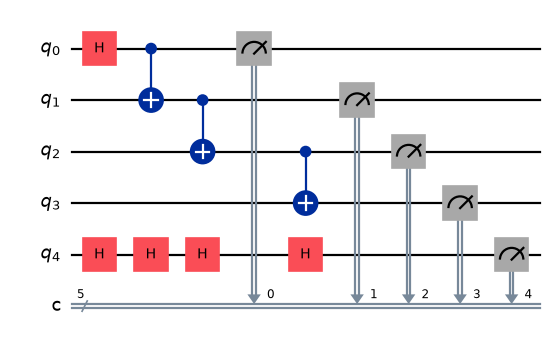

attack 'cx' as executed (1000 gates)         qubits=5    depth=1002    gates=1009    trainable parameters=0
   drawing below: same builder, 4 attack gates; 'cx' on q3,q4 then the GHZ target, then 5 measurements


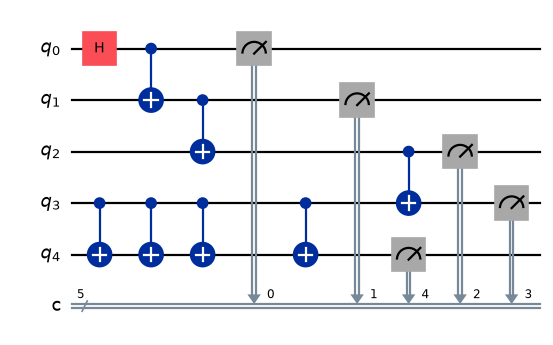

In [9]:
def show(fig):
    display(fig); plt.close(fig)

def stats(name, qc, params=0):
    print(f"{name:<44} qubits={qc.num_qubits:<4} depth={qc.depth():<7} gates={qc.size():<7} trainable parameters={params}")

# ---- 1. target GHZ circuit (Fig. 3) and the two attack circuits (Fig. 4), drawn with 4 attack gates ----
target = ghz_ops(QuantumCircuit(5)); stats("GHZ target (Fig. 3)", target)
show(target.draw("mpl", style="iqp"))
for kind, n_exec, n_draw in [("h", N_H_ATTACK, 4), ("cx", N_CX_ATTACK, 4)]:
    executed = attack_circuit(kind, n_exec); drawn = attack_circuit(kind, n_draw)
    names_exec = [i.operation.name for i in executed.data]; names_draw = [i.operation.name for i in drawn.data]
    assert names_exec == [kind] * n_exec + ["h", "cx", "cx", "cx"] + ["measure"] * 5            # the executed gate list
    assert names_draw == [kind] * n_draw + names_exec[n_exec:]                                  # the drawn copy differs only in the repeat count
    stats(f"attack '{kind}' as executed ({n_exec} gates)", executed)
    print("   drawing below: same builder, 4 attack gates;", f"'{kind}' on " + ("q4" if kind == "h" else "q3,q4"), "then the GHZ target, then 5 measurements")
    show(drawn.draw("mpl", style="iqp"))

attack 'h' (4 gates) transpiled to the fake device qubits=5    depth=13      gates=23      trainable parameters=0
   basis gates after transpilation: {'rz': 10, 'sx': 5, 'measure': 5, 'cx': 3}


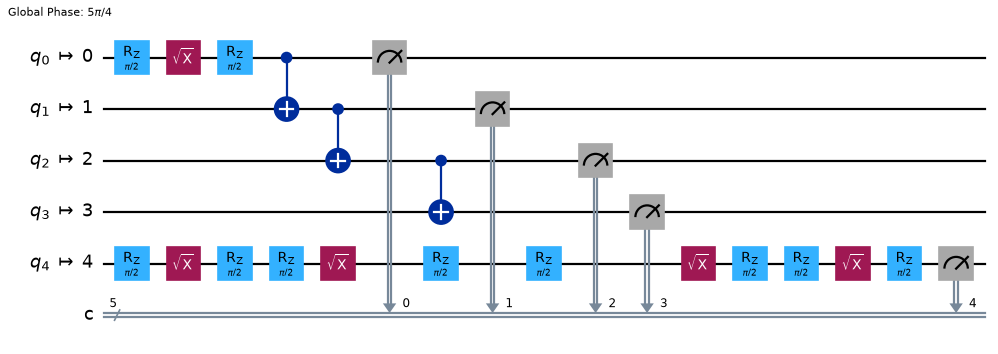

attack 'cx' (4 gates) transpiled to the fake device qubits=5    depth=7       gates=15      trainable parameters=0


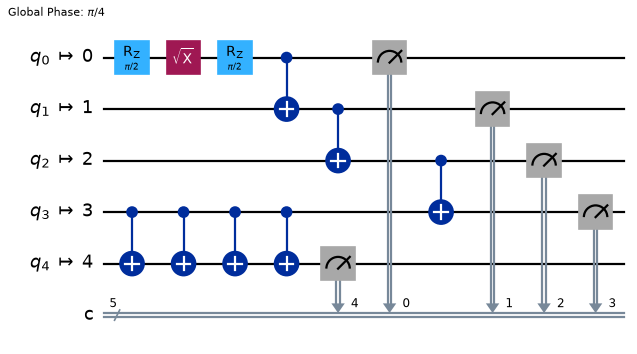

attack 'cx' (2 gates) transpiled to FakeSherbrooke qubits=127  depth=39      gates=96      trainable parameters=0
   basis gates after transpilation: {'rz': 59, 'sx': 22, 'ecr': 5, 'x': 5, 'measure': 5} (active qubits only are drawn)


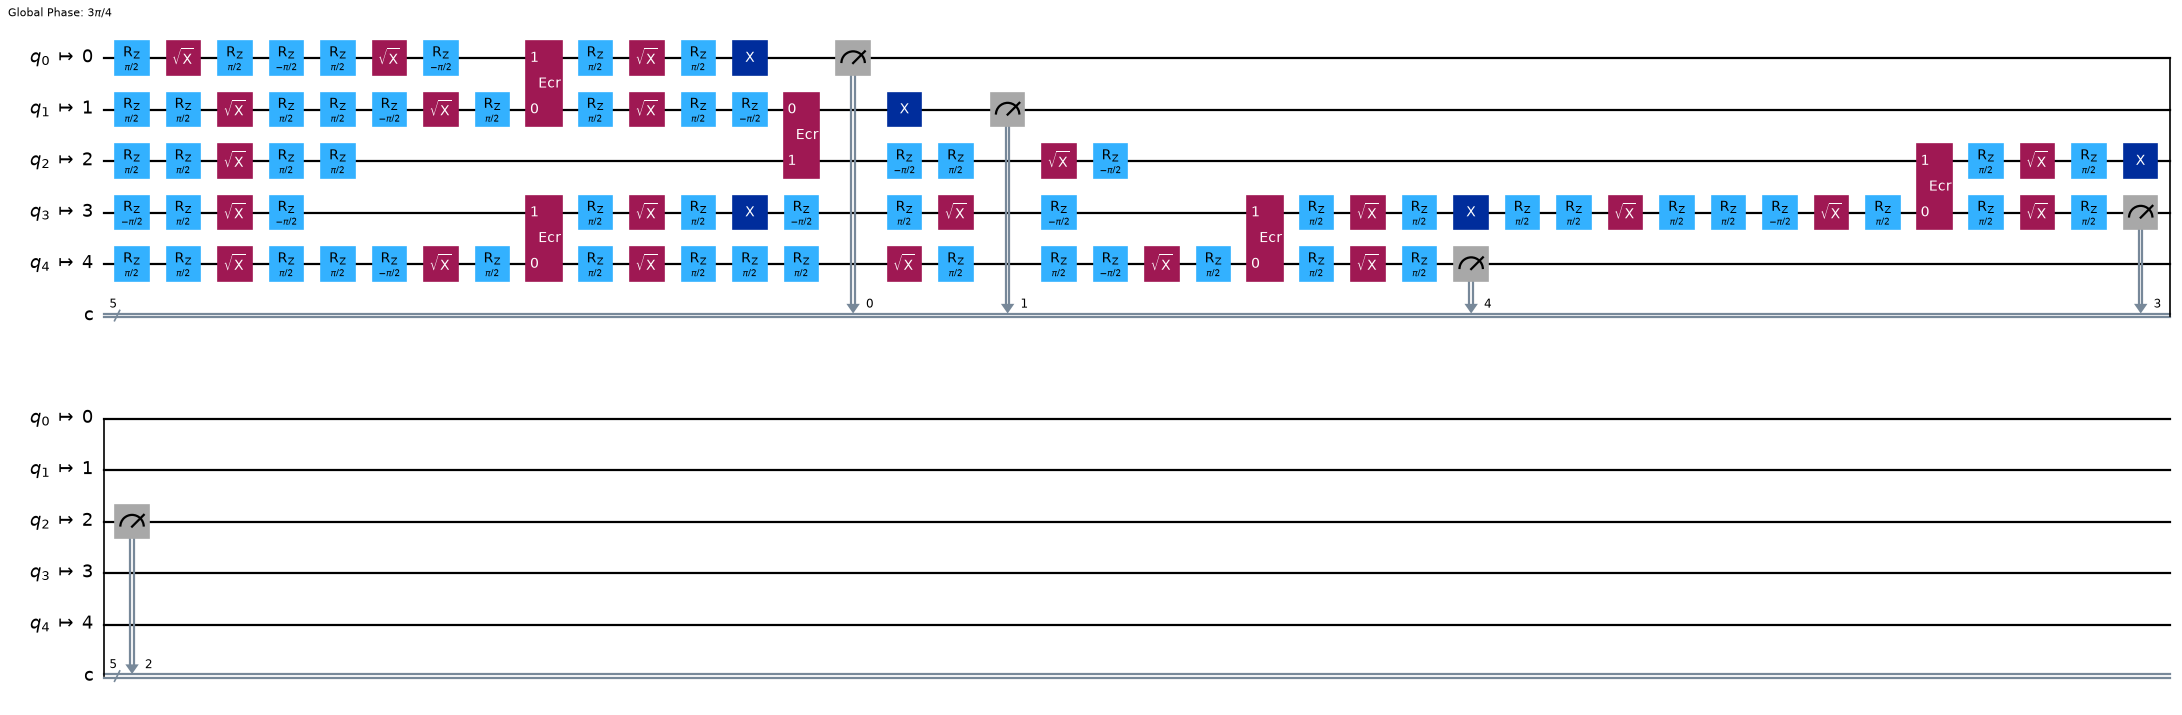

In [10]:
# ---- 2. what the device really runs: the attack circuit transpiled to the fake device (optimisation level 0) ----
tq = PM_FAKE.run(attack_circuit("h", 4)); stats("attack 'h' (4 gates) transpiled to the fake device", tq)
print("   basis gates after transpilation:", dict(tq.count_ops()))
show(tq.draw("mpl", style="iqp", fold=40))
tq = PM_FAKE.run(attack_circuit("cx", 4)); stats("attack 'cx' (4 gates) transpiled to the fake device", tq)
show(tq.draw("mpl", style="iqp", fold=40))
tqs = pm_sherb().run(attack_circuit("cx", 2)); stats("attack 'cx' (2 gates) transpiled to FakeSherbrooke", tqs)
print("   basis gates after transpilation:", dict(tqs.count_ops()), "(active qubits only are drawn)")
show(tqs.draw("mpl", style="iqp", idle_wires=False, fold=40))

modified GHZ target (Fig. 5)                 qubits=5    depth=4       gates=9       trainable parameters=0


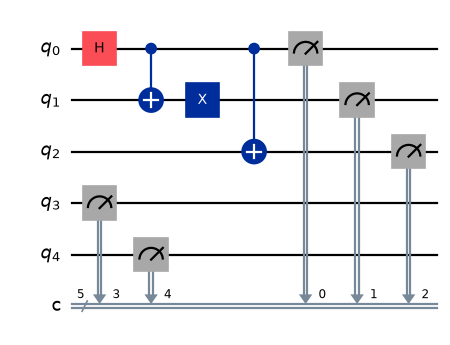

transpiled (honest transpiler)               qubits=5    depth=6       gates=11      trainable parameters=0
transpiled by the tampered pass              qubits=5    depth=7       gates=12      trainable parameters=0
x gates: honest 1 -> tampered 2


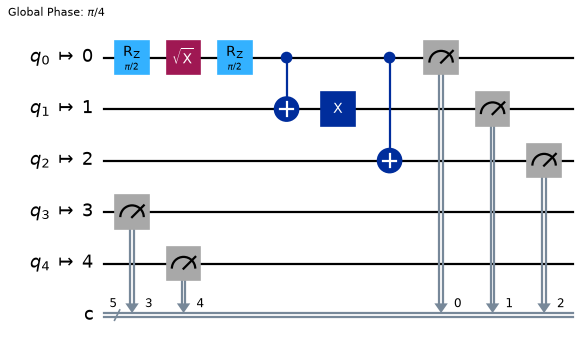

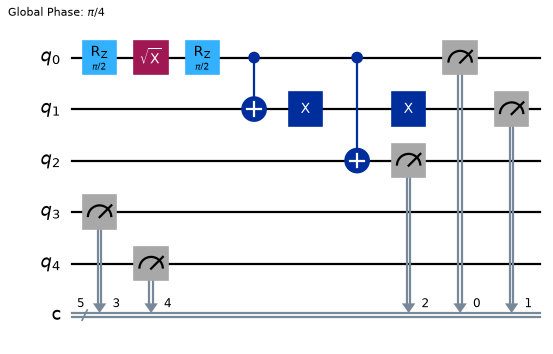

In [11]:
# ---- 3. transpiler-attack circuits (Fig. 5 and Fig. 11) ----
orig = modified_ghz(); stats("modified GHZ target (Fig. 5)", orig)
show(orig.draw("mpl", style="iqp"))
PM_T = generate_preset_pass_manager(optimization_level=0, backend=FAKE, seed_transpiler=SEED)
isa = PM_T.run(orig)
tampered = PassManager([AddXGateOptimizer()]).run(isa)
stats("transpiled (honest transpiler)", isa); stats("transpiled by the tampered pass", tampered)
print("x gates: honest", isa.count_ops().get("x", 0), "-> tampered", tampered.count_ops().get("x", 0))
show(isa.draw("mpl", style="iqp", fold=40)); show(tampered.draw("mpl", style="iqp", fold=40))

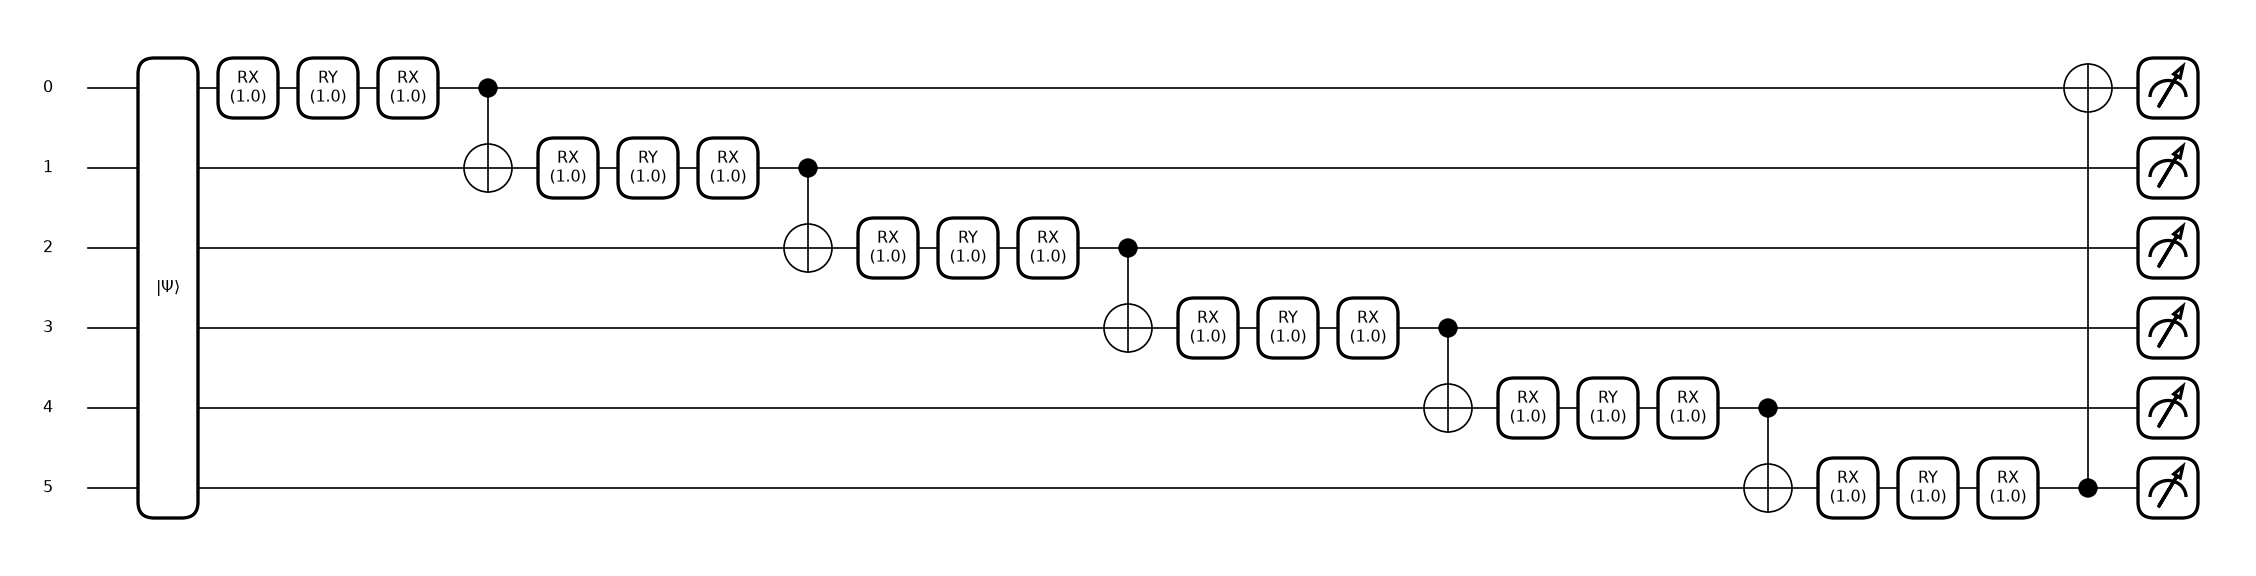

one-pixel model: qubits = 6 | depth after device decomposition = 25 | trainable parameters = 18 (weights) + 1 (bias)
gate counts at device level: {'AmplitudeEmbedding': 1, 'RX': 12, 'RY': 6, 'CNOT': 6}


In [12]:
# ---- 4. one-pixel model: 6 qubits, amplitude embedding + RX/RY/RX + CNOT ring (the QNode that is trained and attacked) ----
w_demo = torch.ones(OP_QUBITS, 3); x_demo = torch.tensor(D_SUMNORM[0])
fig, _ = qml.draw_mpl(op_circuit, decimals=1, level="top")(w_demo, x_demo); show(fig)
spx = qml.specs(op_circuit, level="device")(w_demo, x_demo); sp = spx.resources
print("one-pixel model: qubits =", spx.num_device_wires, "| depth after device decomposition =", sp.depth, "| trainable parameters = %d (weights) + 1 (bias)" % w_demo.numel())
print("gate counts at device level:", dict(sp.gate_types))

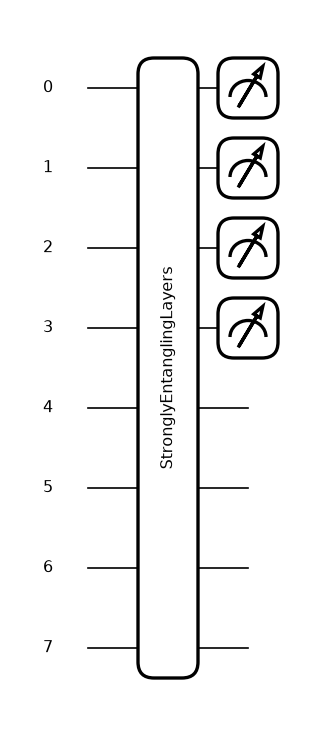

PGD/FGSM model: qubits = 8 | depth = 157 | trainable parameters = 1536 (768 weights + 768 biases) | measured qubits = 4
gate counts of the executed 32-layer circuit: {'Rot': 256, 'CNOT': 256}


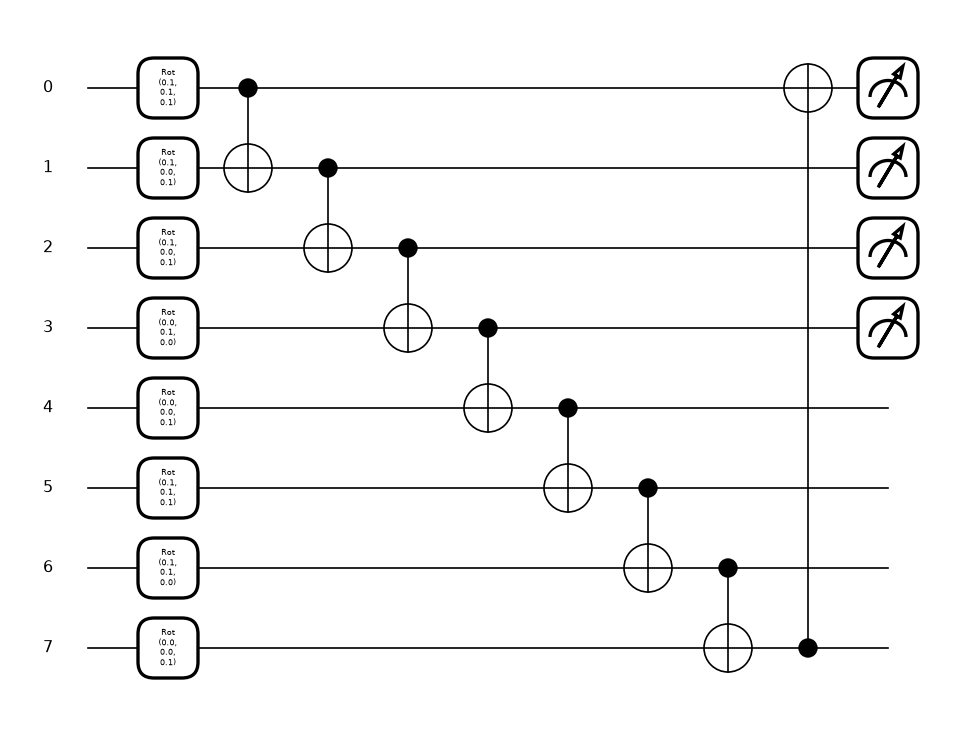

assertion passed: the 32-layer circuit contains exactly 32 x the gates of the decomposed single layer shown above (8 Rot + 8 CNOT per layer)


In [13]:
# ---- 5. PGD/FGSM model: 8 qubits, 32 StronglyEntanglingLayers, 4 qubits measured ----
model_demo = QMLClassifier(SEED)
ang = (model_demo.weights * torch.hstack([torch.tensor(PX_TR[:1])] * PM_REUP).reshape(-1, *PM_SHAPE)[0] + model_demo.bias).detach()
fig, _ = qml.draw_mpl(pm_circuit, level="top")(ang); show(fig)
spx = qml.specs(pm_circuit, level="device")(ang); sp = spx.resources
n_par = sum(p.numel() for p in model_demo.parameters())
print("PGD/FGSM model: qubits =", spx.num_device_wires, "| depth =", sp.depth, "| trainable parameters =", n_par, "(768 weights + 768 biases) | measured qubits = 4")
print("gate counts of the executed 32-layer circuit:", dict(sp.gate_types))
# the drawing above shows the template as one box; one decomposed layer (the same template with 1 layer) shows what it contains:
@qml.qnode(dev_pm)
def one_layer(angles):
    qml.StronglyEntanglingLayers(weights=angles, wires=range(PM_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(PM_CLASSES)]
a1 = ang[:1]
fig, _ = qml.draw_mpl(one_layer, decimals=1, level="device")(a1); show(fig)
sp1 = qml.specs(one_layer, level="device")(a1).resources
assert dict(sp.gate_types)["Rot"] == PM_LAYERS * dict(sp1.gate_types)["Rot"] and dict(sp.gate_types)["CNOT"] == PM_LAYERS * dict(sp1.gate_types)["CNOT"]
print("assertion passed: the 32-layer circuit contains exactly 32 x the gates of the decomposed single layer shown above (8 Rot + 8 CNOT per layer)")

## 3. Experiment 1: crosstalk attack (paper Sec. 3.1 and 4.1, Figures 9 and 10)

**Idea.** On superconducting hardware every gate disturbs the qubits next to it. A tenant who shares a chip with a victim can run gates that mathematically
do nothing (an even number of `H` on an idle qubit, an even number of `CX` between the idle qubit and a qubit of the victim's circuit) and still corrupt the
victim's result. Here both are placed in one circuit next to the victim's GHZ circuit.

**What a simulator can and cannot show.** The Qiskit noise model built from a device attaches an independent depolarising and relaxation error to each
gate and a readout error to each measurement. There is no explicit cross-qubit term, so what the simulation reproduces is the *error accumulation of the
attacker's gates on their own qubits*. For the `H` attack on the idle qubit q4 this flips q4 only (the GHZ qubits are untouched); for the `CX` attack between
q3 and q4 the error lands on q3, which is part of the victim's GHZ state, and scrambles it. Whether the real chip couples more strongly is exactly what the
paper's hardware run (Fig. 10) would test; it cannot be checked here without an IBM token.

First the controls the paper does not show: the ideal simulator (attack gates change nothing) and the noisy device without any attack gates.

ideal simulator, H attack (control)                              1.2s  states >= 1%: 2  P(ideal states) = 1.000


noisy device, no attack (control)                                0.6s  states >= 1%: 3  P(ideal states) = 0.940


noisy device, 10000 H gates on q4 (Fig. 9 left)                  5.5s  states >= 1%: 4  P(ideal states) = 0.752


noisy device, 1000 CX gates on q3,q4 (Fig. 9 right)              0.6s  states >= 1%: 8  P(ideal states) = 0.253


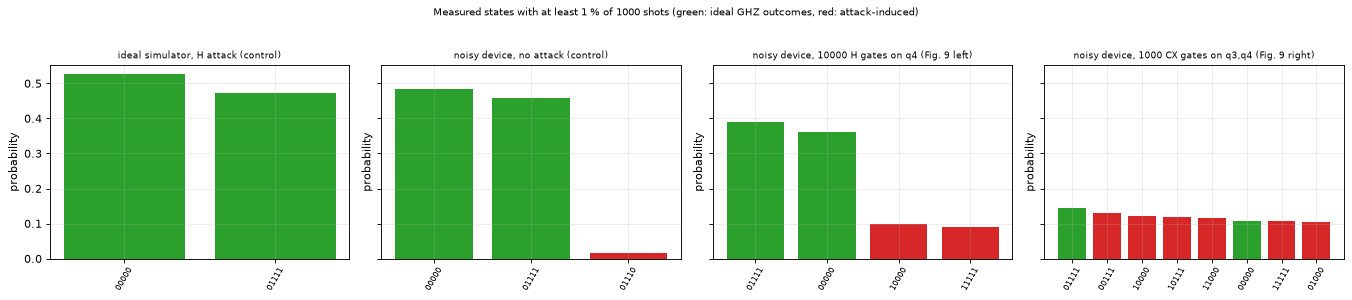

In [14]:
# ---- Fig. 9 on the authors' fake device, with the controls ----
ideal_sim = AerSimulator()
cases = [("ideal simulator, H attack (control)", attack_circuit("h", N_H_ATTACK), AerSimulator(), generate_preset_pass_manager(optimization_level=0, backend=AerSimulator(), seed_transpiler=SEED)),
         ("noisy device, no attack (control)", attack_circuit("h", 0), SIM_FAKE, PM_FAKE),
         (f"noisy device, {N_H_ATTACK} H gates on q4 (Fig. 9 left)", attack_circuit("h", N_H_ATTACK), SIM_FAKE, PM_FAKE),
         (f"noisy device, {N_CX_ATTACK} CX gates on q3,q4 (Fig. 9 right)", attack_circuit("cx", N_CX_ATTACK), SIM_FAKE, PM_FAKE)]
FIG9 = {}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for a, (name, circ, sim, pm) in zip(ax, cases):
    t = time.time(); cnt = run_counts(circ, pm, sim); FIG9[name] = cnt
    p = {k: v / SHOTS for k, v in cnt.items() if v / SHOTS >= 0.01}
    ks = sorted(p, key=lambda k: -p[k])
    a.bar(ks, [p[k] for k in ks], color=["tab:green" if k in IDEAL else "tab:red" for k in ks])
    a.set_title(name, fontsize=8); a.tick_params(axis="x", rotation=60, labelsize=7); a.set_ylabel("probability")
    print(f"{name:<62} {time.time()-t:5.1f}s  states >= 1%: {len(p)}  P(ideal states) = {sum(cnt.get(k,0) for k in IDEAL)/SHOTS:.3f}")
plt.suptitle("Measured states with at least 1 % of 1000 shots (green: ideal GHZ outcomes, red: attack-induced)", y=1.03, fontsize=9)
plt.tight_layout(); plt.show()

In [15]:
# ---- which states appear? compare with the states named in the paper ----
PAPER_H_EXTRA  = ["10000", "11111"]
PAPER_CX_EXTRA = ["00111", "01000", "10000", "10111", "11000", "11111"]
nameH  = f"noisy device, {N_H_ATTACK} H gates on q4 (Fig. 9 left)"
nameCX = f"noisy device, {N_CX_ATTACK} CX gates on q3,q4 (Fig. 9 right)"
pH  = vec(FIG9[nameH]);  pCX = vec(FIG9[nameCX]); p0 = vec(FIG9["noisy device, no attack (control)"])
idx = lambda s: int(s, 2)
tab = pd.DataFrame({"no attack": [p0[idx(s)] for s in ["00000", "01111"] + PAPER_CX_EXTRA],
                    "H attack": [pH[idx(s)] for s in ["00000", "01111"] + PAPER_CX_EXTRA],
                    "CX attack": [pCX[idx(s)] for s in ["00000", "01111"] + PAPER_CX_EXTRA]},
                   index=[f"{s} ({'expected' if s in IDEAL else 'named in the paper'})" for s in ["00000", "01111"] + PAPER_CX_EXTRA]).round(3)
display(tab)
RES["C1_states"] = {s: float(pH[idx(s)]) for s in PAPER_H_EXTRA}
RES["C2_states"] = {s: float(pCX[idx(s)]) for s in PAPER_CX_EXTRA}
RES["C2_ratio"] = min(RES["C2_states"].values()) / min(pCX[idx("00000")], pCX[idx("01111")])
RES["C0_noise_only_max_error_state"] = float(max(p0[i] for i in range(32) if format(i, "05b") not in IDEAL))
other = {format(i, "05b"): round(float(pCX[i]), 3) for i in range(32) if format(i, "05b") not in IDEAL | set(PAPER_CX_EXTRA) and pCX[i] >= 0.02}
print("largest error state without any attack gate: %.3f" % RES["C0_noise_only_max_error_state"])
print("CX attack: smallest named state / smaller expected state = %.2f  (paper: 'almost equal probability')" % RES["C2_ratio"])
print("other CX-attack states above 2 %:", other if other else "none")

,no attack,H attack,CX attack
00000 (expected),0.483,0.361,0.108
01111 (expected),0.457,0.391,0.145
00111 (named in the paper),0.005,0.002,0.129
01000 (named in the paper),0.003,0.005,0.104
10000 (named in the paper),0.000,0.098,0.123
10111 (named in the paper),0.000,0.001,0.118
11000 (named in the paper),0.000,0.001,0.117
11111 (named in the paper),0.000,0.090,0.106


largest error state without any attack gate: 0.015
CX attack: smallest named state / smaller expected state = 0.96  (paper: 'almost equal probability')
other CX-attack states above 2 %: none


no attack                      6.6s  P(ideal states) = 0.898  states >= 1%: 4


10000 H gates on q4           10.2s  P(ideal states) = 0.611  states >= 1%: 7


1000 CX gates on q3,q4         8.4s  P(ideal states) = 0.239  states >= 1%: 8


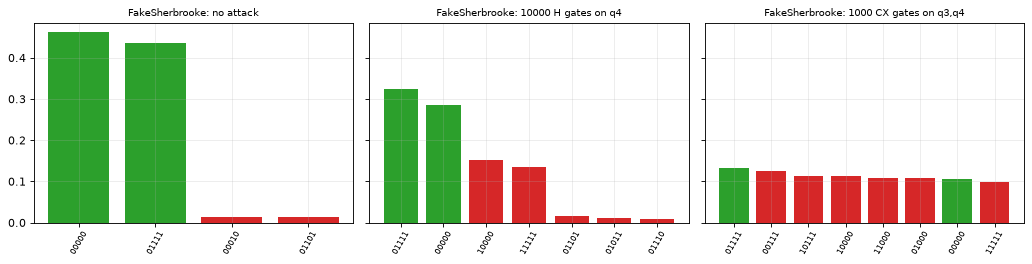

Sherbrooke H attack, paper's extra states : {'10000': 0.151, '11111': 0.135}
Sherbrooke CX attack, paper's extra states: {'00111': 0.125, '01000': 0.108, '10000': 0.112, '10111': 0.113, '11000': 0.109, '11111': 0.099}


In [16]:
# ---- same experiment on the 127-qubit ibm_sherbrooke noise model (qubits 0-4), a second device for robustness ----
FIG9S = {}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for a, (name, circ) in zip(ax, [("no attack", attack_circuit("h", 0)), (f"{N_H_ATTACK} H gates on q4", attack_circuit("h", N_H_ATTACK)),
                                (f"{N_CX_ATTACK} CX gates on q3,q4", attack_circuit("cx", N_CX_ATTACK))]):
    t = time.time(); cnt = run_counts(circ, pm_sherb(), SIM_SHERB); FIG9S[name] = cnt
    p = {k: v / SHOTS for k, v in cnt.items() if v / SHOTS >= 0.01}; ks = sorted(p, key=lambda k: -p[k])
    a.bar(ks, [p[k] for k in ks], color=["tab:green" if k in IDEAL else "tab:red" for k in ks])
    a.set_title("FakeSherbrooke: " + name, fontsize=9); a.tick_params(axis="x", rotation=60, labelsize=7)
    print(f"{name:<28} {time.time()-t:5.1f}s  P(ideal states) = {sum(cnt.get(k,0) for k in IDEAL)/SHOTS:.3f}  states >= 1%: {len(p)}")
plt.tight_layout(); plt.show()
pHs = vec(FIG9S[f"{N_H_ATTACK} H gates on q4"]); pCXs = vec(FIG9S[f"{N_CX_ATTACK} CX gates on q3,q4"])
RES["C1_states_sherb"] = {s: float(pHs[idx(s)]) for s in PAPER_H_EXTRA}
RES["C2_states_sherb"] = {s: float(pCXs[idx(s)]) for s in PAPER_CX_EXTRA}
print("Sherbrooke H attack, paper's extra states :", {k: round(v, 3) for k, v in RES["C1_states_sherb"].items()})
print("Sherbrooke CX attack, paper's extra states:", {k: round(v, 3) for k, v in RES["C2_states_sherb"].items()})

In [17]:
# ---- does a compiler optimisation defeat the attack? (all runs above use optimisation level 0, as the authors do) ----
rows = []
for kind, n in (("h", N_H_ATTACK), ("cx", N_CX_ATTACK)):
    for lvl in (0, 1, 3):
        pm_ = generate_preset_pass_manager(optimization_level=lvl, backend=FAKE, seed_transpiler=SEED)
        tq_ = pm_.run(attack_circuit(kind, n)); cnt_ = SIM_FAKE.run(tq_, shots=SHOTS, seed_simulator=SEED).result().get_counts()
        rows.append({"attack": f"{n} {kind.upper()} gates", "optimisation level": lvl, "gates after transpilation": tq_.size(), "depth": tq_.depth(),
                     "P(ideal states)": sum(cnt_.get(k, 0) for k in IDEAL) / SHOTS})
OPT = pd.DataFrame(rows); display(OPT.round(3)); RES["opt_levels"] = rows

,attack,optimisation level,gates after transpilation,depth,P(ideal states)
0,10000 H gates,0,30011,30001,0.752
1,10000 H gates,1,11,7,0.940
2,10000 H gates,3,11,7,0.937
3,1000 CX gates,0,1011,1002,0.253
4,1000 CX gates,1,11,7,0.940
5,1000 CX gates,3,11,7,0.937


In [18]:
# ---- real hardware (Fig. 10): runs only when an IBM token is configured ----
RES["hardware"] = "not run (IBM_TOKEN empty)"
if IBM_TOKEN:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
        svc = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
        try:
            hw = svc.backend("ibm_sherbrooke")
        except Exception:
            hw = svc.least_busy(operational=True, simulator=False, min_num_qubits=5); print("ibm_sherbrooke unavailable, using", hw.name)
        pm_hw = generate_preset_pass_manager(optimization_level=0, backend=hw, initial_layout=[0, 1, 2, 3, 4], seed_transpiler=SEED)
        sampler = SamplerV2(mode=hw); out = {}
        for name, circ in [("H", attack_circuit("h", N_H_ATTACK)), ("CX", attack_circuit("cx", N_CX_ATTACK))]:
            out[name] = sampler.run([pm_hw.run(circ)], shots=SHOTS).result()[0].data.c.get_counts()
            print(hw.name, name, "attack, top states:", sorted(out[name].items(), key=lambda kv: -kv[1])[:8])
        RES["hardware"] = {"backend": hw.name, **{k: v for k, v in out.items()}}
    except Exception as e:
        RES["hardware"] = f"failed: {type(e).__name__}: {e}"; print(RES["hardware"])
else:
    print("IBM_TOKEN is empty: the real-hardware experiment of Fig. 10 is skipped. Claim C3 is reported as 'cannot be checked'.")

IBM_TOKEN is empty: the real-hardware experiment of Fig. 10 is skipped. Claim C3 is reported as 'cannot be checked'.


### 3.1 How many gates are needed? (paper Sec. 4.1, last paragraph)

The paper loops over the number of attack gates and stops as soon as **more than two** outcomes have more than 10 % of the 1 000 shots, i.e. as soon as an
error state is as visible as one of the two GHZ outcomes ("around 2 300 to 2 400 `H` gates" and "around 140 to 160 `CX` gates" on a fake `ibm_sherbrooke`).

A single loop of 1 000-shot runs is noisy: near the threshold the largest error state sits at about 10 % with a shot-noise spread of about +-1 percentage point, so
the stopping point of one loop moves by several hundred gates between runs. To show this spread honestly, each sweep point is simulated once with 20 000
shots (a precise estimate of the outcome distribution; the simulation cost is dominated by the gates, not by the shots), and the paper's 1 000-shot loop is then
emulated 200 times by drawing 1 000 shots from that distribution. The mean and standard deviation of the 200 stopping points are compared with the paper.

H sweep: 61 points in 357s


CX sweep: 41 points in 193s


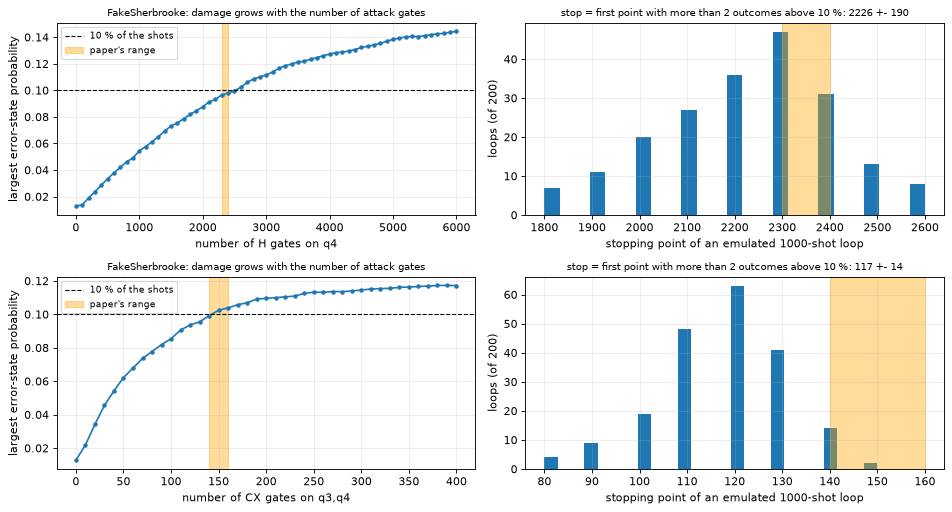

H  gates: emulated loops stop at 2226 +- 190 (expected threshold 2600; 0 loops never stopped); paper 2300-2400
CX gates: emulated loops stop at 117 +- 14 (expected threshold 150; 0 loops never stopped); paper 140-160


In [19]:
def sweep(kind, grid, layout=(0, 1, 2, 3, 4)):
    pm = pm_sherb(layout); P = {}
    for n in grid:
        P[n] = vec(SIM_SHERB.run(pm.run(attack_circuit(kind, n)), shots=HI_SHOTS, seed_simulator=SEED).result().get_counts())
    return P

def virtual_loops(P, grid, n_loops, seed=SEED):
    """Emulate the paper's loop (stop when more than 2 outcomes exceed 10 % of 1000 shots) n_loops times."""
    r = np.random.default_rng(seed); stops = []
    for _ in range(n_loops):
        stop = np.nan
        for n in grid:
            pv = np.clip(P[n], 0, None); c = r.multinomial(SHOTS, pv / pv.sum())
            if (c > SHOTS / 10).sum() > 2:
                stop = n; break
        stops.append(stop)
    return np.array(stops, dtype=float)

def max_err(P, grid):
    mask = np.array([format(i, "05b") not in IDEAL for i in range(32)])
    return np.array([P[n][mask].max() for n in grid]), np.array([(P[n] > 0.1).sum() for n in grid])

t = time.time()
P_H = sweep("h", H_GRID);   print(f"H sweep: {len(H_GRID)} points in {time.time()-t:.0f}s"); t = time.time()
P_CX = sweep("cx", CX_GRID); print(f"CX sweep: {len(CX_GRID)} points in {time.time()-t:.0f}s")
stops_H, stops_CX = virtual_loops(P_H, H_GRID, N_VIRTUAL_LOOPS), virtual_loops(P_CX, CX_GRID, N_VIRTUAL_LOOPS)
eH, kH = max_err(P_H, H_GRID); eC, kC = max_err(P_CX, CX_GRID)
# the 'expected' threshold: first grid point at which the largest error state reaches 10 %
thr = lambda e, g: next((n for n, v in zip(g, e) if v >= 0.10), np.nan)
RES["thr_H"] = dict(mean=float(np.nanmean(stops_H)), std=float(np.nanstd(stops_H)), expected=float(thr(eH, H_GRID)), censored=int(np.isnan(stops_H).sum()))
RES["thr_CX"] = dict(mean=float(np.nanmean(stops_CX)), std=float(np.nanstd(stops_CX)), expected=float(thr(eC, CX_GRID)), censored=int(np.isnan(stops_CX).sum()))

fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
for row, (nm, g, e, k, st, pr) in enumerate([("H gates on q4", H_GRID, eH, kH, stops_H, (2300, 2400)), ("CX gates on q3,q4", CX_GRID, eC, kC, stops_CX, (140, 160))]):
    ax[row, 0].plot(g, e, "o-", ms=3); ax[row, 0].axhline(0.10, color="k", ls="--", lw=1, label="10 % of the shots")
    ax[row, 0].axvspan(*pr, color="orange", alpha=.4, label="paper's range"); ax[row, 0].set_xlabel(f"number of {nm}"); ax[row, 0].set_ylabel("largest error-state probability"); ax[row, 0].legend(fontsize=8)
    ax[row, 0].set_title("FakeSherbrooke: damage grows with the number of attack gates", fontsize=9)
    ax[row, 1].hist(st[~np.isnan(st)], bins=min(25, len(g)), color="tab:blue"); ax[row, 1].axvspan(*pr, color="orange", alpha=.4)
    ax[row, 1].set_xlabel("stopping point of an emulated 1000-shot loop"); ax[row, 1].set_ylabel("loops (of %d)" % N_VIRTUAL_LOOPS)
    ax[row, 1].set_title(f"stop = first point with more than 2 outcomes above 10 %: {np.nanmean(st):.0f} +- {np.nanstd(st):.0f}", fontsize=9)
plt.tight_layout(); plt.show()
print("H  gates: emulated loops stop at %.0f +- %.0f (expected threshold %.0f; %d loops never stopped); paper 2300-2400" % (RES["thr_H"]["mean"], RES["thr_H"]["std"], RES["thr_H"]["expected"], RES["thr_H"]["censored"]))
print("CX gates: emulated loops stop at %.0f +- %.0f (expected threshold %.0f; %d loops never stopped); paper 140-160" % (RES["thr_CX"]["mean"], RES["thr_CX"]["std"], RES["thr_CX"]["expected"], RES["thr_CX"]["censored"]))

In [20]:
# ---- sensitivity: other 5-qubit lines of ibm_sherbrooke (the paper does not say which qubits it used) ----
RES["extra_layouts"] = []
if N_EXTRA_LAYOUTS:
    edges = {tuple(sorted(e)) for e in SHERB.coupling_map}; nbr = {}
    for a_, b_ in edges: nbr.setdefault(a_, []).append(b_); nbr.setdefault(b_, []).append(a_)
    r = np.random.default_rng(SEED); used = {0, 1, 2, 3, 4}; layouts = []
    while len(layouts) < N_EXTRA_LAYOUTS:
        path = [int(r.choice(sorted(set(nbr) - used)))]
        while len(path) < 5:
            nxt = [q for q in nbr[path[-1]] if q not in path and q not in used]
            if not nxt: break
            path.append(int(r.choice(nxt)))
        if len(path) == 5:
            layouts.append(path); used |= set(path)
    rows = []
    for lay in layouts:
        PH, PC = sweep("h", EXTRA_H_GRID, lay), sweep("cx", EXTRA_CX_GRID, lay)
        sH, sC = virtual_loops(PH, EXTRA_H_GRID, 100), virtual_loops(PC, EXTRA_CX_GRID, 100)
        rows.append({"physical qubits": lay, "H gates (mean stop)": np.nanmean(sH), "CX gates (mean stop)": np.nanmean(sC),
                     "H loops censored": int(np.isnan(sH).sum()), "CX loops censored": int(np.isnan(sC).sum())})
    RES["extra_layouts"] = rows; display(pd.DataFrame(rows).round(0))
else:
    print("FAST_MODE: sensitivity runs on other qubit lines are skipped (N_EXTRA_LAYOUTS = 0).")

,physical qubits,H gates (mean stop),CX gates (mean stop),H loops censored,CX loops censored
0,"[15, 22, 21, 20, 19]",2568.0,193.0,0,0
1,"[61, 60, 53, 41, 40]",1708.0,111.0,0,0


## 4. Experiment 2: transpiler attack (paper Sec. 3.2 and 4.2, Figures 11 and 12)

A quantum program is handed to a cloud service as a high-level circuit and *transpiled* into the gates of the target chip. Qiskit lets anyone add a custom
`TransformationPass` to that pipeline. The authors' pass walks over the circuit's DAG and replaces each `x` node by two `x` nodes, which cancel: the victim's
`X` gate disappears. Their target circuit is a 3-qubit GHZ-type circuit with an extra `X` on q1, with ideal outputs `00010` and `00101`; without the `X` the
outputs would be `00000` and `00111`.

The paper's countermeasure (Sec. 5, "inverse execution") is implemented as well: append the inverse of the circuit that was *supposed* to run to the circuit that
*does* run; an honest transpilation gives `00000` with certainty, a tampered one does not. The authors' repository does this with the two transpiled
circuits; here the check is made against the original, untranspiled program, which is what a user can do without trusting the transpiler.

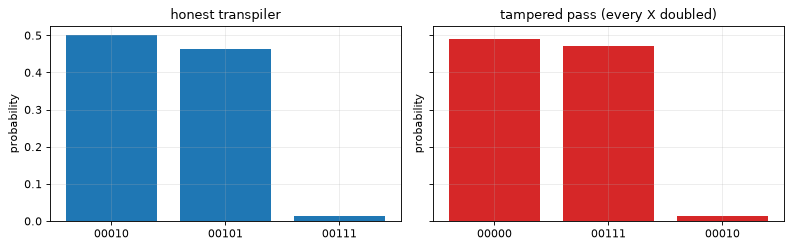

honest  top-2: [('00010', 501), ('00101', 464)]
tampered top-2: [('00000', 491), ('00111', 470)]


honest transpiler      P(|00000>) after inverse execution = 0.917 | exact operator equivalence = True


tampered transpiler    P(|00000>) after inverse execution = 0.013 | exact operator equivalence = False


In [21]:
# ---- run honest and tampered circuit on the noisy fake device (Fig. 12) ----
c_honest = SIM_FAKE.run(isa, shots=SHOTS, seed_simulator=SEED).result().get_counts()
c_tamper = SIM_FAKE.run(tampered, shots=SHOTS, seed_simulator=SEED).result().get_counts()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a, (nm, c) in zip(ax, [("honest transpiler", c_honest), ("tampered pass (every X doubled)", c_tamper)]):
    p = {k: v / SHOTS for k, v in c.items() if v / SHOTS >= 0.01}; ks = sorted(p, key=lambda k: -p[k])
    a.bar(ks, [p[k] for k in ks], color="tab:blue" if "honest" in nm else "tab:red"); a.set_title(nm); a.set_ylabel("probability")
plt.tight_layout(); plt.show()
top = lambda c: sorted(c.items(), key=lambda kv: -kv[1])[:2]
print("honest  top-2:", top(c_honest)); print("tampered top-2:", top(c_tamper))
RES["C6"] = {"honest_top2": [k for k, _ in top(c_honest)], "tampered_top2": [k for k, _ in top(c_tamper)],
             "tampered_prob": [v / SHOTS for _, v in top(c_tamper)]}

# ---- countermeasure: inverse execution against the ORIGINAL program ----
orig_nm = modified_ghz(measure=False)
def inverse_check(candidate, name):
    cand = candidate.remove_final_measurements(inplace=False)
    chk = QuantumCircuit(5, 5); chk.compose(cand, inplace=True); chk.compose(orig_nm.inverse(), inplace=True); chk.measure(range(5), range(5))
    cnt = SIM_FAKE.run(PM_FAKE.run(chk), shots=SHOTS, seed_simulator=SEED).result().get_counts()
    p0 = cnt.get("00000", 0) / SHOTS
    eq = Operator(cand).equiv(Operator(orig_nm))
    print(f"{name:<22} P(|00000>) after inverse execution = {p0:.3f} | exact operator equivalence = {eq}")
    return p0, eq
RES["inv_honest"] = inverse_check(isa, "honest transpiler")
RES["inv_tampered"] = inverse_check(tampered, "tampered transpiler")

In [22]:
# ---- when does the attack work? the pass only sees what is a literal 'x' node in the transpiled circuit ----
rows = []
for dev_name, backend, simu in [("generic 5q (basis cx,x,sx,rz)", FAKE, AerSimulator()), ("FakeSherbrooke (basis ecr,x,sx,rz)", SHERB, AerSimulator())]:
    for lvl in (0, 1, 3):
        pm_ = generate_preset_pass_manager(optimization_level=lvl, backend=backend, initial_layout=[0, 1, 2, 3, 4], seed_transpiler=SEED)
        h = pm_.run(orig); t_ = PassManager([AddXGateOptimizer()]).run(h)
        ch = simu.run(h, shots=4000, seed_simulator=SEED).result().get_counts(); ct = simu.run(t_, shots=4000, seed_simulator=SEED).result().get_counts()
        tp = lambda c: "/".join(sorted(k for k, _ in sorted(c.items(), key=lambda kv: -kv[1])[:2]))
        rows.append({"device": dev_name, "optimisation level": lvl, "x gates honest": h.count_ops().get("x", 0), "x gates tampered": t_.count_ops().get("x", 0),
                     "ideal top-2 honest": tp(ch), "ideal top-2 tampered": tp(ct), "output changed": tp(ch) != tp(ct)})
display(pd.DataFrame(rows))
RES["basis_table"] = rows

,device,optimisation level,x gates honest,x gates tampered,ideal top-2 honest,ideal top-2 tampered,output changed
0,"generic 5q (basis cx,x,sx,rz)",0,1,2,00010/00101,00000/00111,True
1,"generic 5q (basis cx,x,sx,rz)",1,1,2,00010/00101,00000/00111,True
2,"generic 5q (basis cx,x,sx,rz)",3,1,2,00010/00101,00000/00111,True
3,"FakeSherbrooke (basis ecr,x,sx,rz)",0,3,6,00010/00101,00011/00100,True
4,"FakeSherbrooke (basis ecr,x,sx,rz)",1,0,0,00010/00101,00010/00101,False
5,"FakeSherbrooke (basis ecr,x,sx,rz)",3,0,0,00010/00101,00010/00101,False


## 5. Experiment 3: one-pixel attack on a 6-qubit classifier (paper Sec. 3.3 and 4.3)

**Model (authors' code).** The 64 pixels of a digit 0/1 image (divided by their sum) become the 64 amplitudes of 6 qubits. A trainable layer of `RX, RY, RX`
rotations and a ring of `CNOT`s follows; the output is the sum of the six `<Z>` values plus a bias, trained with a square loss against the labels 0 and 1 (gradient
descent, step 0.3, 200 steps, all weights initialised with 1). A test image is classified as 1 if the output is at least 0.5.

**Attack.** Pick a random test image. Take random pixels one at a time (each change is applied to the *original* image, as in the authors' loop) and stop at the first
one that makes the prediction wrong. Two pixel-change rules are run: the **repository rule** (in the sum-normalised units the pixels are about 0.01-0.05, and a pixel
`> 0.5` becomes 0.5 while any other becomes 1.0, i.e. a value 20 to 100 times the others) and the **paper-text rule** (black <-> white on the raw 0-16 scale: a light pixel,
raw value below 8, becomes 16, a dark one becomes 0).

The paper only "inspected if the attack was successful" on one image. To quantify, for every correctly classified test image all 64 single-pixel changes are tried
and the fraction of images with at least one successful pixel, and the fraction of successful pixels, are reported. The same attack is run against three classical models
trained on the same L2-normalised images.

In [23]:
def train_one_pixel(Xtr, ytr, steps=OP_STEPS, lr=OP_LR):
    w = torch.ones(OP_QUBITS, 3, requires_grad=True); b = torch.zeros((), requires_grad=True)   # authors: np.ones, bias 0
    opt = torch.optim.SGD([w, b], lr=lr)                                                          # plain gradient descent, step 0.3
    X, y = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float64); hist = []
    for s in range(steps):
        opt.zero_grad(); loss = ((y - (op_circuit(w, X) + b)) ** 2).mean(); loss.backward(); opt.step(); hist.append(loss.item())
    return w.detach(), b.detach(), hist

def op_predict(w, b, X):
    with torch.no_grad():
        return (op_circuit(w, torch.tensor(np.atleast_2d(X))) + b >= 0.5).long().numpy()

def pixel_variants(x_raw, rule):
    """All 64 single-pixel changes of one image (raw 0-16 units in), returned in sum-normalised units, shape (64, 64)."""
    if rule == "repo":                                   # authors' code, applied to the sum-normalised image
        xn = x_raw / x_raw.sum(); out = np.repeat(xn[None], 64, 0)
        for p in range(64):
            out[p, p] = 0.5 if xn[p] > 0.5 else 1.0
        return out
    out = np.repeat(x_raw[None], 64, 0)                  # paper text: light -> black (16), dark -> white (0); CHOICE: threshold 8 on 0..16
    for p in range(64):
        out[p, p] = 16.0 if x_raw[p] < 8 else 0.0
    return out / out.sum(axis=1, keepdims=True)

l2n = lambda X: X / np.linalg.norm(X, axis=1, keepdims=True)
def fit_classical(Xtr, ytr, seed):
    return {"LogReg": LogisticRegression(max_iter=2000, random_state=seed).fit(l2n(Xtr), ytr),
            "SVC(rbf)": SVC(kernel="rbf", random_state=seed).fit(l2n(Xtr), ytr),
            "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1).fit(l2n(Xtr), ytr)}

def attack_stats(predict, X_raw_te, y_te, rule):
    """predict: callable on sum-normalised images. Returns per-image flip matrices for correctly classified images."""
    ok = np.where(predict(X_raw_te / X_raw_te.sum(1, keepdims=True)) == y_te)[0]
    allv = np.concatenate([pixel_variants(X_raw_te[i], rule) for i in ok])          # one batched call for all images
    flips = (predict(allv).reshape(len(ok), 64) != y_te[ok][:, None])
    return ok, flips

OP_ROWS, OP_MAIN = [], None
t = time.time()
for sd in OP_SEEDS:
    Xtr, Xte, ytr, yte, Rtr, Rte = train_test_split(D_SUMNORM, D_Y, D_RAW, train_size=0.8, random_state=sd)
    w, b, hist = train_one_pixel(Xtr, ytr)
    models = {"quantum (6 qubits)": lambda X, w=w, b=b: op_predict(w, b, X)}
    for name, clf in fit_classical(Xtr, ytr, sd).items():
        models[name] = lambda X, clf=clf: clf.predict(l2n(np.atleast_2d(X)))
    for mname, pred in models.items():
        acc = float((pred(Xte) == yte).mean())
        for rule in ("repo", "paper"):
            ok, fl = attack_stats(pred, Rte, yte, rule)
            OP_ROWS.append({"seed": sd, "model": mname, "rule": rule, "test acc": acc, "images attacked": len(ok),
                            "images fooled by >=1 pixel": float(fl.any(1).mean()), "pixels that fool": float(fl.mean())})
    if sd == OP_SEEDS[0]:
        OP_MAIN = dict(w=w, b=b, hist=hist, Xte=Xte, yte=yte, Rte=Rte, models=models)
print(f"one-pixel experiment: {len(OP_SEEDS)} seeds in {time.time()-t:.0f}s")
OPdf = pd.DataFrame(OP_ROWS)
agg = OPdf.groupby(["model", "rule"])[["test acc", "images fooled by >=1 pixel", "pixels that fool"]].agg(["mean", "std"]).round(3)
display(agg)
RES["op_table"] = OPdf

one-pixel experiment: 5 seeds in 335s


test acc        images fooled by >=1 pixel         \
                             mean    std                       mean    std   
model              rule                                                      
LogReg             paper    1.000  0.000                      0.003  0.006   
                   repo     1.000  0.000                      0.989  0.012   
RandomForest       paper    1.000  0.000                      0.006  0.008   
                   repo     1.000  0.000                      0.544  0.052   
SVC(rbf)           paper    1.000  0.000                      0.000  0.000   
                   repo     1.000  0.000                      0.497  0.036   
quantum (6 qubits) paper    0.997  0.006                      0.120  0.041   
                   repo     0.997  0.006                      1.000  0.000   

                         pixels that fool         
                                     mean    std  
model              rule                           
LogReg             paper            0.000  0.000  
                   repo             0.333  0.024  
RandomForest       paper            0.000  0.000  
                   repo             0.026  0.017  
SVC(rbf)           paper            0.000  0.000  
                   repo             0.497  0.036  
quantum (6 qubits) paper            0.013  0.007  
                   repo             0.497  0.025

training loss: 2.6537 -> 0.0254 | test accuracy 1.000 (rounded output, 72 test images)
random test image #6: true label 0, clean prediction 0


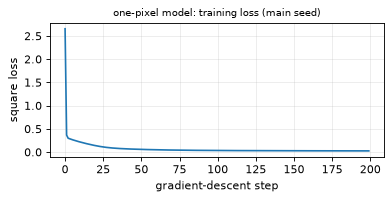

rule 'repo': attack successful after 13 random pixel(s) (pixel 62); 8 of 64 single-pixel changes flip this image


rule 'paper': no single-pixel change flips this image (attack failed on it)


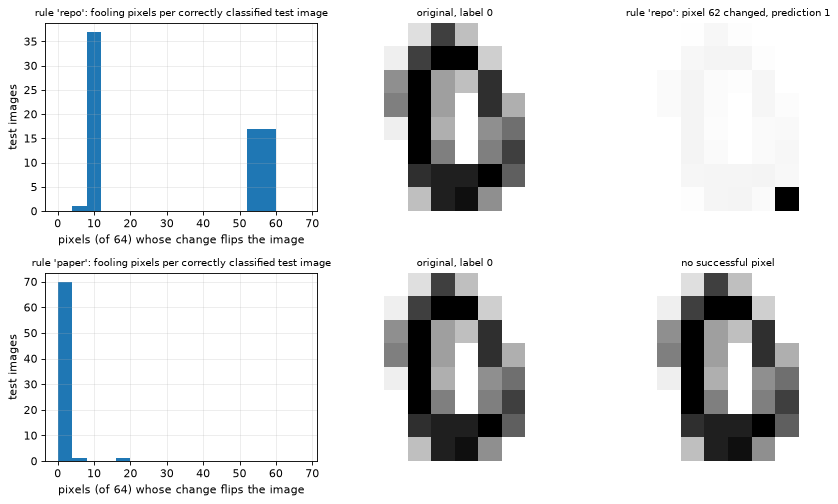

In [24]:
# ---- the paper's protocol on one random test image (main seed), and the attack gallery ----
w, b, hist, Rte, yte = OP_MAIN["w"], OP_MAIN["b"], OP_MAIN["hist"], OP_MAIN["Rte"], OP_MAIN["yte"]
qpred = OP_MAIN["models"]["quantum (6 qubits)"]
print("training loss: %.4f -> %.4f | test accuracy %.3f (rounded output, %d test images)" % (hist[0], hist[-1], (qpred(Rte / Rte.sum(1, keepdims=True)) == yte).mean(), len(yte)))
r = np.random.default_rng(SEED)
attack_idx = int(r.integers(len(yte)))                    # "randomly choose one image from the test set"
x0, y0 = Rte[attack_idx], int(yte[attack_idx])
print(f"random test image #{attack_idx}: true label {y0}, clean prediction {int(qpred(x0 / x0.sum())[0])}")
ONE = {}
fig, ax = plt.subplots(1, 1, figsize=(5, 2.6)); ax.plot(hist); ax.set_xlabel("gradient-descent step"); ax.set_ylabel("square loss"); ax.set_title("one-pixel model: training loss (main seed)", fontsize=9)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(2, 3, figsize=(11, 6.4))
for row, rule in enumerate(("repo", "paper")):
    var = pixel_variants(x0, rule); preds = qpred(var)
    order = r.permutation(64); tries, hit = 0, None
    for p in order:                                       # random pixel order, stop at the first success (the paper's loop, without repeats)
        tries += 1
        if preds[p] != y0: hit = int(p); break
    ONE[rule] = dict(success=hit is not None, tries=tries if hit is not None else None, n_flipping=int((preds != y0).sum()))
    print(f"rule '{rule}': " + (f"attack successful after {tries} random pixel(s) (pixel {hit}); {ONE[rule]['n_flipping']} of 64 single-pixel changes flip this image"
                              if hit is not None else "no single-pixel change flips this image (attack failed on it)"))
    ok, fl = attack_stats(qpred, Rte, yte, rule)
    ax[row, 0].hist(fl.sum(1), bins=range(0, 70, 4)); ax[row, 0].set_xlabel("pixels (of 64) whose change flips the image"); ax[row, 0].set_ylabel("test images")
    ax[row, 0].set_title(f"rule '{rule}': fooling pixels per correctly classified test image", fontsize=9)
    ax[row, 1].imshow(x0.reshape(8, 8), cmap="gray_r"); ax[row, 1].set_title(f"original, label {y0}", fontsize=9); ax[row, 1].axis("off")
    if hit is not None:
        ax[row, 2].imshow(var[hit].reshape(8, 8), cmap="gray_r")
        ax[row, 2].set_title(f"rule '{rule}': pixel {hit} changed, prediction {int(preds[hit])}", fontsize=9)
    else:
        ax[row, 2].imshow(x0.reshape(8, 8), cmap="gray_r"); ax[row, 2].set_title("no successful pixel", fontsize=9)
    ax[row, 2].axis("off")
plt.tight_layout(); plt.show()
RES["op_one_image"] = ONE

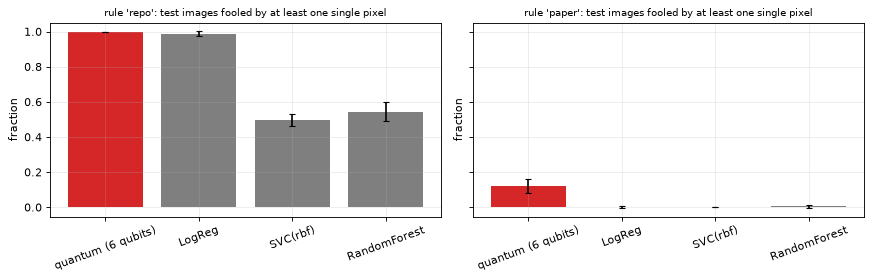

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, rule in zip(ax, ("repo", "paper")):
    sub = OPdf[OPdf.rule == rule].groupby("model")["images fooled by >=1 pixel"].agg(["mean", "std"]).reindex(["quantum (6 qubits)", "LogReg", "SVC(rbf)", "RandomForest"])
    a.bar(sub.index, sub["mean"], yerr=sub["std"].fillna(0), color=["tab:red", "tab:gray", "tab:gray", "tab:gray"], capsize=3)
    a.set_title(f"rule '{rule}': test images fooled by at least one single pixel", fontsize=9); a.set_ylabel("fraction"); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 6. Experiment 4: PGD and FGSM on the 8-qubit plus-minus classifier (paper Sec. 3.3 and 4.3, Figures 13 and 14)

**Model.** Eight qubits and 32 `StronglyEntanglingLayers`; the 256 pixels are repeated three times and reshaped to the layer-parameter shape (32, 8, 3); the rotation
angles are `weights * pixels + bias` (data re-uploading in every gate); the four class scores are `<Z>` of qubits 0-3. Cross-entropy, Adam with learning rate 0.1, batches of 20.
Because PennyLane's `default.qubit` supports broadcasting, a whole batch is simulated in one call (the authors loop over images; the numbers are identical).

**Attacks (white box, L-infinity).** FGSM: `x + eps * sign(grad_x loss)`. PGD: ten steps of size 0.01 along the gradient sign, projected to `|delta| <= eps` after each step, no random start.
With `eps = 0.1` on pixel values in [0, 1].

**Four representatives.** The first image of every class in the training file (one image per class), as in the authors' notebook.

**Baseline.** A small classical MLP (256-32-4, ReLU) trained on the same images and attacked in the same way.

In [26]:
def batches_acc(model, X, y, bs=50):
    with torch.no_grad():
        pred = torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])
    return float((pred == y).double().mean()), pred

def train_qml(seed, X, y, Xv, yv, epochs, log=True):
    torch.manual_seed(seed)
    model = QMLClassifier(seed); opt = torch.optim.Adam(model.parameters(), lr=PM_LR)
    n_b = len(X) // PM_BATCH; hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(X)).reshape(n_b, -1); t = time.time()
        for it in range(n_b):
            opt.zero_grad(); l = F.cross_entropy(model(X[perm[it]]), y[perm[it]]); l.backward(); opt.step()
        va, _ = batches_acc(model, Xv, yv); hist.append((ep + 1, l.item(), va))
        if log: print(f"  epoch {ep+1}/{epochs}  last batch loss {l.item():.4f}  test acc {va:.3f}  ({time.time()-t:.0f}s)", flush=True)
    return model, hist

def fgsm(model, x, y, eps):
    d = torch.zeros_like(x, requires_grad=True)
    g, = torch.autograd.grad(F.cross_entropy(model(x + d), y), d)
    return eps * g.sign()

def pgd(model, x, y, eps, alpha=ALPHA, iters=PGD_ITERS):
    d = torch.zeros_like(x)
    for _ in range(iters):
        d.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(x + d), y), d)
        d = (d.detach() + alpha * g.sign()).clamp(-eps, eps)
    return d.detach()

def attacked(model, x, y, attack, eps, bs=50):
    return torch.cat([attack(model, x[i:i + bs], y[i:i + bs], eps) for i in range(0, len(x), bs)])

XTR, YTR = torch.tensor(PX_TR), torch.tensor(PY_TR); XTE, YTE = torch.tensor(PX_TE), torch.tensor(PY_TE)
reps_idx = [int(np.where(PM_YTR == c)[0][0]) for c in range(4)]                 # first image of each class in the training file
XREP, YREP = torch.tensor(PM_XTR[reps_idx].reshape(4, -1)), torch.tensor(PM_YTR[reps_idx])
print("representatives (training-file indices):", reps_idx, "| classes", YREP.tolist())
t0 = time.time()
QM, QHIST = train_qml(SEED, XTR, YTR, XTE, YTE, PM_EPOCHS)
print(f"quantum model trained in {time.time()-t0:.0f}s")

representatives (training-file indices): [0, 10, 7, 1] | classes [0, 1, 2, 3]


  epoch 1/4  last batch loss 1.2760  test acc 0.760  (59s)


  epoch 2/4  last batch loss 1.2147  test acc 0.940  (51s)


  epoch 3/4  last batch loss 1.1617  test acc 0.980  (51s)


  epoch 4/4  last batch loss 1.0882  test acc 0.960  (48s)


quantum model trained in 210s


In [27]:
# ---- classical baseline on the same images ----
def train_mlp(seed, X, y, epochs=MLP_EPOCHS):
    torch.manual_seed(seed)
    m = torch.nn.Sequential(torch.nn.Linear(256, 32), torch.nn.ReLU(), torch.nn.Linear(32, PM_CLASSES)); opt = torch.optim.Adam(m.parameters(), lr=0.01)
    n_b = len(X) // PM_BATCH
    for ep in range(epochs):
        perm = torch.randperm(len(X)).reshape(n_b, -1)
        for it in range(n_b):
            opt.zero_grad(); F.cross_entropy(m(X[perm[it]]), y[perm[it]]).backward(); opt.step()
    return m
MLP = train_mlp(SEED, XTR, YTR)
acc_q, pred_q = batches_acc(QM, XTE, YTE); acc_c, pred_c = batches_acc(MLP, XTE, YTE)
print(f"clean test accuracy ({len(XTE)} images): quantum {acc_q:.3f} | classical MLP {acc_c:.3f}")
repq = batches_acc(QM, XREP, YREP)[1]; repc = batches_acc(MLP, XREP, YREP)[1]
print("representatives, clean: quantum predicts", repq.tolist(), "| MLP predicts", repc.tolist(), "| truth", YREP.tolist())

clean test accuracy (50 images): quantum 0.960 | classical MLP 1.000


representatives, clean: quantum predicts [0, 1, 2, 3] | MLP predicts [0, 1, 2, 3] | truth [0, 1, 2, 3]


PGD   quantum  representatives misclassified: 4/4  | accuracy on 50 test images under attack: 0.000  (113s)


PGD   MLP      representatives misclassified: 3/4  | accuracy on 50 test images under attack: 0.080  (114s)


FGSM  quantum  representatives misclassified: 4/4  | accuracy on 50 test images under attack: 0.020  (134s)


FGSM  MLP      representatives misclassified: 3/4  | accuracy on 50 test images under attack: 0.140  (134s)


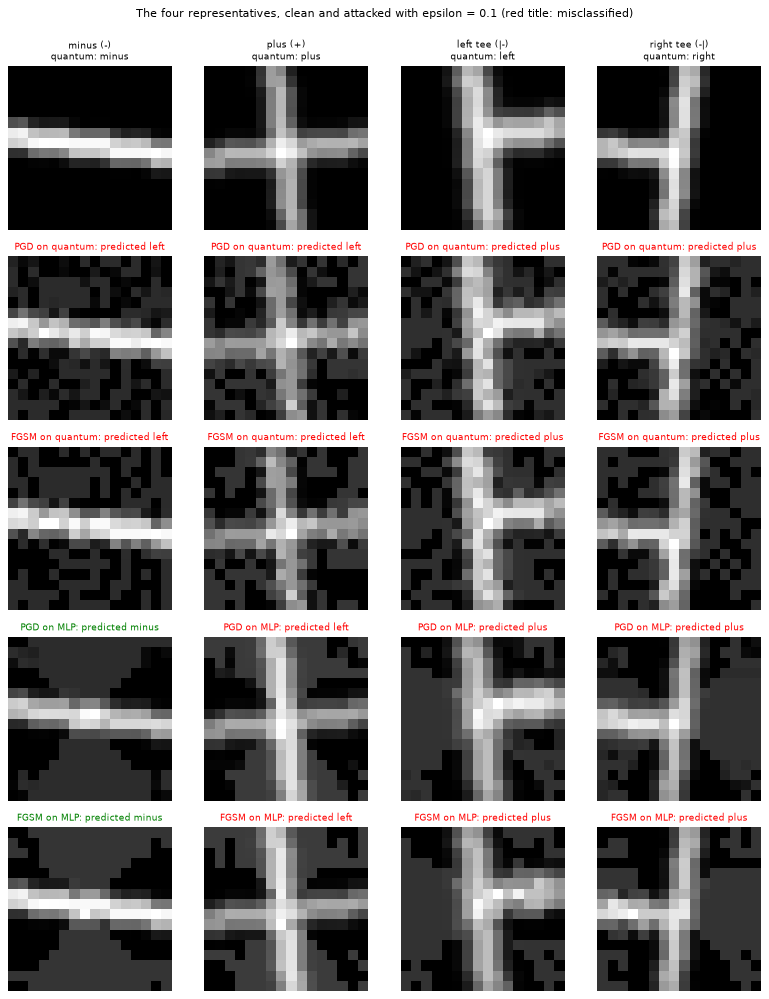

In [28]:
# ---- attacks at eps = 0.1: the four representatives (Fig. 13/14) and the whole test set ----
t = time.time()
ATT = {}
for aname, afn in (("PGD", pgd), ("FGSM", fgsm)):
    for mname, model in (("quantum", QM), ("MLP", MLP)):
        dr = afn(model, XREP, YREP, EPS); pr = model(XREP + dr).argmax(1)
        dt = attacked(model, XTE, YTE, afn, EPS); acc, _ = batches_acc(model, XTE + dt, YTE)
        ATT[(aname, mname)] = dict(rep_adv=XREP + dr, rep_pred=pr.tolist(), rep_wrong=int((pr != YREP).sum()), test_acc=acc)
        print(f"{aname:<5} {mname:<8} representatives misclassified: {int((pr != YREP).sum())}/4  | accuracy on {len(XTE)} test images under attack: {acc:.3f}  ({time.time()-t:.0f}s)", flush=True)
RES["pm"] = dict(clean_q=acc_q, clean_c=acc_c, att=ATT, hist=QHIST)

fig, ax = plt.subplots(5, 4, figsize=(10, 12.5))
rows = [("clean", XREP, repq, repc)]
for c in range(4):
    ax[0, c].imshow(XREP[c].reshape(16, 16), cmap="gray"); ax[0, c].set_title(f"{PM_NAMES[c]}\nquantum: {PM_NAMES[int(repq[c])].split()[0]}", fontsize=8)
for r_, (aname, mname) in enumerate([("PGD", "quantum"), ("FGSM", "quantum"), ("PGD", "MLP"), ("FGSM", "MLP")], start=1):
    d_ = ATT[(aname, mname)]
    for c in range(4):
        ax[r_, c].imshow(d_["rep_adv"][c].reshape(16, 16).detach(), cmap="gray")
        ok_ = d_["rep_pred"][c] == c
        ax[r_, c].set_title(f"{aname} on {mname}: predicted {PM_NAMES[d_['rep_pred'][c]].split()[0]}", fontsize=8, color="green" if ok_ else "red")
for a in ax.ravel(): a.axis("off")
plt.suptitle("The four representatives, clean and attacked with epsilon = 0.1 (red title: misclassified)", y=0.995, fontsize=10)
plt.tight_layout(); plt.show()

eps 0.025 done (13s)


eps 0.05 done (114s)


eps 0.1 done (222s)


eps 0.2 done (233s)


attack   FGSM           PGD        
model     MLP quantum   MLP quantum
epsilon                            
0.025    1.00    0.86  1.00     NaN
0.050    0.76    0.58  0.76    0.52
0.100    0.14    0.02  0.08    0.00
0.200    0.02    0.00  0.08     NaN

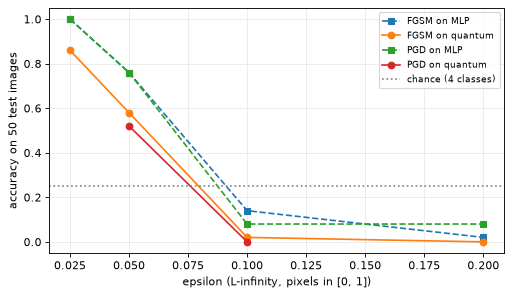

In [29]:
# ---- accuracy versus epsilon (an extension: the paper uses one epsilon) ----
t = time.time(); sweep_rows = []
QPGD_EPS = {EPS} if FAST_MODE else {EPS, 0.05}
for eps in EPS_SWEEP:
    for aname, afn in (("FGSM", fgsm), ("PGD", pgd)):
        for mname, model in (("quantum", QM), ("MLP", MLP)):
            if mname == "quantum" and aname == "PGD" and eps not in QPGD_EPS:
                continue                                   # PGD on the quantum model is the expensive one (10 gradient passes)
            d_ = attacked(model, XTE, YTE, afn, eps); sweep_rows.append({"attack": aname, "model": mname, "epsilon": eps, "accuracy": batches_acc(model, XTE + d_, YTE)[0]})
    print(f"eps {eps} done ({time.time()-t:.0f}s)", flush=True)
SW = pd.DataFrame(sweep_rows); display(SW.pivot_table(index="epsilon", columns=["attack", "model"], values="accuracy").round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for (aname, mname), g in SW.groupby(["attack", "model"]):
    ax.plot(g.epsilon, g.accuracy, "o-" if mname == "quantum" else "s--", label=f"{aname} on {mname}")
ax.axhline(0.25, color="gray", ls=":", label="chance (4 classes)"); ax.set_xlabel("epsilon (L-infinity, pixels in [0, 1])"); ax.set_ylabel(f"accuracy on {len(XTE)} test images"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
RES["pm_sweep"] = SW

## 7. Side-by-side comparison with the paper

Verdict rules, fixed before looking at the numbers: a qualitative claim is *reproduced* if every named state reaches at least 5 % of the shots (and, where the paper says
"almost equal probability", the smallest named state has at least half the probability of the smaller ideal state); a threshold is *reproduced* if the mean emulated stopping
point lies within 20 % of the middle of the paper's range; an "n of 4" claim is *reproduced* only for exactly 3 of 4. "Not reached" means the effect is smaller than claimed,
"exceeded" larger; "cannot be checked" means the experiment needs hardware or the paper gives no number.

In [30]:
def verdict_states(d, thr=0.05):
    return "reproduced" if all(v >= thr for v in d.values()) else "not reached"
def verdict_thr(mean, lo, hi, tol=0.2):
    mid = (lo + hi) / 2
    if np.isnan(mean): return "not reached (loop never stopped)"
    return "reproduced" if abs(mean - mid) <= tol * mid else ("not reached (needs more gates)" if mean > mid else "exceeded (fewer gates)")
def verdict_n4(n, claim=3):
    return "reproduced" if n == claim else ("not reached" if n < claim else "exceeded")

rows = []
c2 = verdict_states(RES["C2_states"]) if RES["C2_ratio"] >= 0.5 else "not reached"
rows.append(["C1  H attack adds 10000 and 11111 (Fig. 9 left)", "both states present", "10000: %.3f, 11111: %.3f (generic fake device); Sherbrooke: %.3f, %.3f" % (*RES["C1_states"].values(), *RES["C1_states_sherb"].values()), verdict_states(RES["C1_states"])])
rows.append(["C2  CX attack adds six states with almost equal probability (Fig. 9 right)", "00111 01000 10000 10111 11000 11111", "smallest named state %.3f; ratio to the smaller ideal state %.2f; Sherbrooke: smallest named state %.3f" % (min(RES["C2_states"].values()), RES["C2_ratio"], min(RES["C2_states_sherb"].values())), c2])
rows.append(["C3  same on the real ibm_sherbrooke (Fig. 10)", "histograms similar to the simulation", str(RES["hardware"])[:80], "cannot be checked" if isinstance(RES["hardware"], str) and RES["hardware"].startswith("not run") else "see histogram"])
rows.append(["C4  H gates needed for >2 outcomes above 10 %", "about 2300-2400", "%.0f +- %.0f (emulated loops); expected threshold %.0f" % (RES["thr_H"]["mean"], RES["thr_H"]["std"], RES["thr_H"]["expected"]), verdict_thr(RES["thr_H"]["mean"], 2300, 2400)])
rows.append(["C5  CX gates needed", "about 140-160", "%.0f +- %.0f (emulated loops); expected threshold %.0f" % (RES["thr_CX"]["mean"], RES["thr_CX"]["std"], RES["thr_CX"]["expected"]), verdict_thr(RES["thr_CX"]["mean"], 140, 160)])
ok6 = set(RES["C6"]["honest_top2"]) == {"00010", "00101"} and set(RES["C6"]["tampered_top2"]) == {"00000", "00111"} and min(RES["C6"]["tampered_prob"]) > 0.4
rows.append(["C6  tampered pass gives 00000 / 00111 with ~equal probability (Fig. 12)", "00000 and 00111, ~50 % each", "honest %s; tampered %s with %s" % (RES["C6"]["honest_top2"], RES["C6"]["tampered_top2"], np.round(RES["C6"]["tampered_prob"], 3).tolist()), "reproduced" if ok6 else "not reached"])
rows.append(["C6b countermeasure: inverse execution detects the tampering (Sec. 5)", "mismatch visible", "P(|00000>): honest %.3f, tampered %.3f; operator equivalence: %s / %s" % (RES["inv_honest"][0], RES["inv_tampered"][0], RES["inv_honest"][1], RES["inv_tampered"][1]), "reproduced" if RES["inv_honest"][0] > 0.8 and RES["inv_tampered"][0] < 0.2 and RES["inv_honest"][1] and not RES["inv_tampered"][1] else "not reached"])
one = RES["op_one_image"]
opm = RES["op_table"].query("model == 'quantum (6 qubits)'").groupby("rule")[["images fooled by >=1 pixel"]].mean()
rows.append(["C7  one-pixel attack misclassifies a random test image", "attack successful (no number)", "repo rule: %s, paper-text rule: %s on the random image; images fooled over all test images: repo %.2f, paper-text %.2f" % (
    ("yes after %d pixel(s)" % one["repo"]["tries"]) if one["repo"]["success"] else "no", ("yes after %d pixel(s)" % one["paper"]["tries"]) if one["paper"]["success"] else "no",
    opm.loc["repo"].iloc[0], opm.loc["paper"].iloc[0]), "reproduced" if one["repo"]["success"] else "not reached on this image (see success rates)"])
for tag, aname in (("C8  PGD", "PGD"), ("C9  FGSM", "FGSM")):
    d_ = RES["pm"]["att"][(aname, "quantum")]
    rows.append([f"{tag}: 3 of the 4 representatives misclassified (Fig. {13 if aname=='PGD' else 14})", "3 / 4", f"{d_['rep_wrong']} / 4 on the representatives; accuracy on {len(XTE)} test images under attack {d_['test_acc']:.2f} (clean {RES['pm']['clean_q']:.2f}); classical MLP: {RES['pm']['att'][(aname,'MLP')]['rep_wrong']} / 4, {RES['pm']['att'][(aname,'MLP')]['test_acc']:.2f}", verdict_n4(d_["rep_wrong"])])
# values from the authors' own notebook outputs (not paper claims): clean 0.98, PGD 0.02, FGSM 0.14 on 50 test images
def v_rep(x, ref, tol=0.10): return "consistent with repo output" if abs(x - ref) <= tol else ("higher than repo output" if x > ref else "lower than repo output")
rows.append(["R1  authors' repo output: clean test accuracy 0.98 (50 images)", "0.98 (repo, not in the paper)", f"{RES['pm']['clean_q']:.2f} ({len(XTE)} images)", v_rep(RES["pm"]["clean_q"], 0.98) if not FAST_MODE else "FAST_MODE: smaller model budget, not comparable"])
rows.append(["R2  authors' repo output: accuracy under PGD 0.02", "0.02 (repo, not in the paper)", f"{RES['pm']['att'][('PGD','quantum')]['test_acc']:.2f}", v_rep(RES["pm"]["att"][("PGD", "quantum")]["test_acc"], 0.02) if not FAST_MODE else "FAST_MODE: smaller model budget, not comparable"])
rows.append(["R3  authors' repo output: accuracy under FGSM 0.14", "0.14 (repo, not in the paper)", f"{RES['pm']['att'][('FGSM','quantum')]['test_acc']:.2f}", v_rep(RES["pm"]["att"][("FGSM", "quantum")]["test_acc"], 0.14) if not FAST_MODE else "FAST_MODE: smaller model budget, not comparable"])
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 250)
display(CMP.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
for _, r_ in CMP.iterrows(): print(f"[{r_.verdict}] {r_.claim} | paper: {r_.paper} | here: {r_["this notebook"]}")
print("\nTotal notebook runtime: %.1f minutes" % ((time.time() - T0) / 60))

,claim,paper,this notebook,verdict
0,C1 H attack adds 10000 and 11111 (Fig. 9 left),both states present,"10000: 0.098, 11111: 0.090 (generic fake device); Sherbrooke: 0.151, 0.135",reproduced
1,C2 CX attack adds six states with almost equal probability (Fig. 9 right),00111 01000 10000 10111 11000 11111,smallest named state 0.104; ratio to the smaller ideal state 0.96; Sherbrooke: smallest named state 0.099,reproduced
2,C3 same on the real ibm_sherbrooke (Fig. 10),histograms similar to the simulation,not run (IBM_TOKEN empty),cannot be checked
3,C4 H gates needed for >2 outcomes above 10 %,about 2300-2400,2226 +- 190 (emulated loops); expected threshold 2600,reproduced
4,C5 CX gates needed,about 140-160,117 +- 14 (emulated loops); expected threshold 150,exceeded (fewer gates)
5,C6 tampered pass gives 00000 / 00111 with ~equal probability (Fig. 12),"00000 and 00111, ~50 % each","honest ['00010', '00101']; tampered ['00000', '00111'] with [0.491, 0.47]",reproduced
6,C6b countermeasure: inverse execution detects the tampering (Sec. 5),mismatch visible,"P(|00000>): honest 0.917, tampered 0.013; operator equivalence: True / False",reproduced
7,C7 one-pixel attack misclassifies a random test image,attack successful (no number),"repo rule: yes after 13 pixel(s), paper-text rule: no on the random image; images fooled over all test images: repo 1.00, paper-text 0.12",reproduced
8,C8 PGD: 3 of the 4 representatives misclassified (Fig. 13),3 / 4,"4 / 4 on the representatives; accuracy on 50 test images under attack 0.00 (clean 0.96); classical MLP: 3 / 4, 0.08",exceeded
9,C9 FGSM: 3 of the 4 representatives misclassified (Fig. 14),3 / 4,"4 / 4 on the representatives; accuracy on 50 test images under attack 0.02 (clean 0.96); classical MLP: 3 / 4, 0.14",exceeded


[reproduced] C1  H attack adds 10000 and 11111 (Fig. 9 left) | paper: both states present | here: 10000: 0.098, 11111: 0.090 (generic fake device); Sherbrooke: 0.151, 0.135
[reproduced] C2  CX attack adds six states with almost equal probability (Fig. 9 right) | paper: 00111 01000 10000 10111 11000 11111 | here: smallest named state 0.104; ratio to the smaller ideal state 0.96; Sherbrooke: smallest named state 0.099
[cannot be checked] C3  same on the real ibm_sherbrooke (Fig. 10) | paper: histograms similar to the simulation | here: not run (IBM_TOKEN empty)
[reproduced] C4  H gates needed for >2 outcomes above 10 % | paper: about 2300-2400 | here: 2226 +- 190 (emulated loops); expected threshold 2600
[exceeded (fewer gates)] C5  CX gates needed | paper: about 140-160 | here: 117 +- 14 (emulated loops); expected threshold 150
[reproduced] C6  tampered pass gives 00000 / 00111 with ~equal probability (Fig. 12) | paper: 00000 and 00111, ~50 % each | here: honest ['00010', '00101']; tamp

## 8. Reading the paper critically

* **The crosstalk attack is mostly a noise-accumulation effect here.** In a simulator whose noise model is local to each gate, 10 000 `H` gates on the idle qubit q4 only
  randomise q4; the GHZ qubits are not touched, so "crosstalk" in the physical sense (a gate on one qubit shifting the frequency or phase of a neighbour) is not
  demonstrated by the simulation, only that a long sequence of nominally neutral gates builds up error. The `CX` attack does corrupt the victim because q3 belongs to the
  victim's circuit; the six extra states are the product of a fully scrambled q3 and q4 with the two GHZ branches. The real-hardware run is the part that could show
  genuine crosstalk, and it is not reproducible without an IBM account (and backends in the public fleet change over time).
* **The thresholds depend on the device snapshot and on the qubits.** The 10 % rule is applied to one 1 000-shot run per point; near the threshold the stopping point scatters
  by hundreds of gates between repeats, so "2 300 to 2 400" is a single draw, not a measurement with an error bar. The fake-backend noise data also change with each release of
  `qiskit-ibm-runtime`. In the full run the emulated `H` loops stop at about 2 230 +- 190 gates (the paper's range lies inside this spread), while the largest error state
  reaches exactly 10 % only at about 2 600 gates; for `CX` the emulated loops stop at about 117 +- 14 gates, a little earlier than the paper's 140-160 (the largest error state
  reaches 10 % at about 150 gates), because the stopping rule fires as soon as shot noise lifts one of several near-equal error states above 100 counts. The sensitivity table
  shows that the qubits matter more than the shot noise: two other 5-qubit lines of the same fake chip give clearly different thresholds.
* **Gate counts of 140 `CX` or a few thousand `H` are not stealthy.** A cloud provider can reject circuits with thousands of pointless gates or run an optimiser that removes them
  (here the transpiler is deliberately run at optimisation level 0; the table after Fig. 9 shows that at optimisation level 1 or 3 the 30 000 gates collapse to 11 and the
  attack disappears completely). The attack needs either no optimisation or gates that are not cancellable.
* **The transpiler attack is trivial by design and fragile.** The pass only finds literal `x` nodes: on a device whose native two-qubit gate is `ecr` the compiler already uses `x` inside
  every CNOT decomposition and the pass breaks the circuit in other places; at optimisation level 1 or 3 the `X` is merged into other rotations and the pass finds nothing
  (table in section 4; on the generic `cx` device the `X` survives all levels and the attack works). The paper's remark that a tenant "can add a pass" assumes a transpiler the attacker controls; a user who transpiles locally and submits the ISA circuit is not exposed
  to this attack at all, and the inverse-execution check catches it.
* **One pixel is not "one small change" for this model.** The repository rule overwrites a pixel with a value 20-100 times larger than all others, so after amplitude normalisation the input is almost a
  single basis state. That is a large, visible perturbation rather than an imperceptible one. The paper-text rule (black/white) changes a pixel by at most the full range and fools far fewer images.
  A single successful image proves little; the success rates over the test set and the classical baselines (section 5) give the context the paper defers to future work.
* **PGD and FGSM with epsilon 0.1 are strong here.** With amplitude-like data re-uploading and pixel values mostly 0, an L-infinity change of 0.1 on every one of the 256 pixels is a large
  perturbation of the normalised input. The classical MLP trained on the same images is fooled too (section 6; in the full run its accuracy under PGD/FGSM at epsilon 0.1 is 0.08 / 0.14
  against 0.00 / 0.02 for the quantum model, and at epsilon 0.05 the quantum model is somewhat less robust, 0.52 against 0.76 under PGD), so the vulnerability shown is that of gradient-based
  attacks in general, not a specific quantum weakness. Note that the quantum model reaches 4 of 4 misclassified representatives where the paper reports 3 of 4: with one model and four
  images that difference is within what another seed would change.
  Four representatives are not a statistic; the accuracy over all test images and the epsilon sweep are the better numbers.
* **Text and code disagree on the data size.** The text says 1 000 training and 200 test images; the authors' notebook trains on 200 and tests on 50. The notebook follows the code.
* **Model training is a single seed** for the 8-qubit model because each PGD run costs minutes on a CPU simulator; the 3 of 4 outcome on four images can change with the seed.
* **No defence is evaluated.** The countermeasure section of the paper is a list of recommendations; only the inverse-execution check is tested here.

## 9. Exercises

1. **Optimisation level.** Re-run the crosstalk sweep with `optimization_level=3` for the transpiler. Does the attack still work? Explain what the optimiser removes.
2. **Order of gates.** Put the attack gates *after* the GHZ circuit (and before the measurement). Does the result histogram change? Which part of the noise model explains it?
3. **Real crosstalk.** Add an explicit ZZ-coupling error term to the noise model (for example a `NoiseModel` whose `cx` error also acts on a spectator qubit) and check whether the `H` attack on q4 now damages the GHZ qubits.
4. **One-pixel, two pixels.** Extend the one-pixel attack to the best pair of pixels. How many pairs are needed to fool every correctly classified test image under the paper-text rule?
5. **Adversarial training.** Retrain the 8-qubit model with PGD examples mixed into every batch (the authors' repository does this with 10 % of the data) and measure the accuracy under PGD at epsilon 0.1 and 0.2. Does the quantum model become more robust than the MLP trained the same way?